# Выученная политика: сценарии, NII, MtM и $\Delta V$

Ноутбук принимает конечногоризонтный и стационарный чекпоинт. Укажите `RUN_DIR` ниже. Для стационарной политики `VIS_YEARS` задаёт только длину графиков, не срок жизни банка. Цвет каждой линии — **одна** траектория физической ставки и соответствующая ей динамика банка. Графики иллюстрируют поведение политики, но не доказывают её оптимальности.

В модели $x_t=(r_t,F_t,Y_t,E_t)$, $L_t=L_0e^{gt}$ и $D_t=D_0e^{gt}$; старые чекпоинты имеют $g=0$. Денежная позиция $C_t=E_t+D_t-L_t$, а $f_t$ — доля **новых выдач** под fixed. Поэтому $f_t$ и доля fixed в уже существующей книге $F_t/L_t$ различаются.

Мгновенный **чистый процентный доход** без операционных расходов и дивидендов:

$$n(t,x)=Y+r(L_t-F)+rC-(\beta r+s_D)D_t-s_B(-C)^+.$$

На первом графике $NII_{1y}^{\mathrm{real}}(t)=\int_t^{t+1}n(X_s)\,ds$ — *реализованный впоследствии* доход по конкретному сценарию при выученной политике. Это иллюстрация денежных потоков, **не** определение $\Delta NII_{1y}$, используемое в исследовании. Ниже есть отдельный график $\Delta NII_{1y}$ с замороженным балансом и шоком +100 б.п.

**MtM** — стоимость текущего баланса при немедленной переоценке по кривой $Q$:

$$\operatorname{MtM}(t,x)=C+\big[L_t-F+(Y+\mu F)A_Q(r)\big]-D_t
=E-F+(Y+\mu F)A_Q(r).$$

Существующие кредиты переоцениваются, депозиты в этой упрощённой модели стоят по номиналу. Это модельный аналог EVE, без поведенческой оценки депозитов и других статей баланса. Показатель `E/L` ниже назван модельным CAR: его знаменатель — весь кредитный портфель, а не регуляторные RWA.
При росте книги, зависящем от ставки, на траекториях используется фактический баланс $L_t$; для контрфактических срезов баланс задаётся явно.


In [85]:
from pathlib import Path
import json, math, os, sys
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

RUN_ID = None # gamma=1, eta=0.005; смените на другой run_XXXX
RUN_DIR = "runs/stationary_rate_growth_refined"  # относительно risk_sensitive; None — старый RUN_ID
VIS_YEARS = 10.0  # только окно визуализации для стационарной политики
SEED = 20261016
N_PATHS = 32 if os.environ.get("IRRBB_NOTEBOOK_SMOKE") else 256
POLICY_GRID = 33       # используем сетку действий, сохранённую в чекпоинте, если она иная
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Ноутбук запускается из корня проекта или из любой вложенной папки.
root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "continuous_time_irrbb/risk_sensitive/solver.py").exists()), None)
if root is None:
    raise FileNotFoundError("Запустите Jupyter внутри проекта IRRBB")
sys.path.insert(0, str(root))
from types import SimpleNamespace
from continuous_time_irrbb.risk_sensitive.solver import FittedSolution
from continuous_time_irrbb.risk_sensitive.stationary_solver import StationarySolution

run_dir = Path(RUN_DIR) if RUN_DIR else Path("runs/sweep_equal_spreads") / RUN_ID
if not run_dir.is_absolute(): run_dir = root / "continuous_time_irrbb/risk_sensitive" / run_dir
report = json.loads((run_dir / "report.json").read_text(encoding="utf-8"))
dtype = torch.float64 if report["dtype"] == "float64" else torch.float32
STATIONARY_MODE = "stationary_config" in report
if STATIONARY_MODE:
    raw_solution = StationarySolution.load(run_dir / "stationary_solution.pt", device=DEVICE, dtype=dtype)
    class StationaryNotebookSolution:
        def __init__(self, raw, years):
            self.raw, self.environment = raw, raw.environment
            steps = round(years / raw.config.dt)
            if steps < 1: raise ValueError("VIS_YEARS должно быть не меньше одного шага")
            self.config = SimpleNamespace(steps=steps, dt=raw.config.dt,
                horizon=steps*raw.config.dt, action_count=raw.config.action_count,
                risk_aversion=raw.config.risk_aversion_per_loan/raw.environment.p.loans)
        def action(self, layer, state, *, action_count=None, loans=None):
            return self.raw.action(state, time=layer*self.config.dt, action_count=action_count, loans=loans)
        def value(self, layer, state, *, loans=None):
            return self.raw.value(state, time=layer*self.config.dt, loans=loans)
    solution = StationaryNotebookSolution(raw_solution, VIS_YEARS)
else:
    solution = FittedSolution.load(run_dir / "solution.pt", device=DEVICE, dtype=dtype)
env, cfg, p = solution.environment, solution.config, solution.environment.p
def snapshot_loans(layer):
    return p.loans if STATIONARY_MODE and p.growth_rate_sensitivity else env.loans_at(layer*cfg.dt)

def snapshot_deposits(loans):
    return loans*p.deposits/p.loans

def batch_loans(states, loans):
    return torch.full(states.shape[:-1], float(loans), device=states.device, dtype=states.dtype)

RUN_ID = run_dir.name
POLICY_GRID = cfg.action_count
plt.style.use("seaborn-v0_8-whitegrid")
print(f"{RUN_ID}: {'stationary' if STATIONARY_MODE else 'finite horizon'}, "
      f"gamma_0={cfg.risk_aversion:g}, eta={p.floating_demand_slope:g}, "
      f"device={DEVICE}, plot years={cfg.horizon:g}, dt={cfg.dt:.4f}, actions={POLICY_GRID}")
print("Начальное состояние:", report["reference_state"])
print("Диагностика качества:", report.get("quality_flags") or report.get("warning") or "нет")


stationary_rate_growth_refined: stationary, gamma_0=0.1, eta=0.01, device=cuda, plot years=10, dt=0.2500, actions=33
Начальное состояние: [0.07999999821186066, 50.0, 5.625, 12.0]
Диагностика качества: Held-out Bellman residual is diagnostic, not a global optimality bound. If converged is false, do not treat the saved policy as solved.


## Траектории при одной и той же начальной книге

Сначала моделируем множество реализаций процесса ставки под $P$, применяя к каждой обученную обратную связь. Для рисунка выбираем путь с низкой конечной ставкой, с высокой, близкий к среднему и с наибольшим диапазоном ставок. Выбор экстремальных путей нужен для иллюстрации, не для оценки вероятности событий. Все линии начинаются из одного состояния.

In [86]:
@torch.no_grad()
def instantaneous_nii(x, time=0.0, loans=None):
    balance = env._loan_balance(x, time, loans)
    return env.profit(x, time, balance) + p.operating_cost*snapshot_deposits(balance)

@torch.no_grad()
def simulate_policy(n_paths=N_PATHS, seed=SEED):
    generator = torch.Generator(device="cpu").manual_seed(seed)
    shocks = torch.randn((cfg.steps, n_paths), generator=generator, dtype=dtype).to(DEVICE)
    x = torch.tensor(report["reference_state"], device=DEVICE, dtype=dtype).expand(n_paths, -1).clone()
    loans = torch.full((n_paths,), p.loans, device=DEVICE, dtype=dtype)
    states, loan_paths, actions, nii_mid, profit_mid, dividend_mid = [x.cpu().numpy().copy()], [loans.cpu().numpy().copy()], [], [], [], []
    half_decay = math.exp(-p.amortization * cfg.dt / 2)
    for k in range(cfg.steps):
        f = solution.action(k, x, action_count=POLICY_GRID, **({"loans": loans} if STATIONARY_MODE else {}))
        t = k * cfg.dt
        step = env.step(x, f, shocks[k], cfg.dt, time=t, validate=False, loans=loans)
        mid_issuance = step.midpoint_loans - half_decay * loans
        mid_f = half_decay * x[:, 1] + mid_issuance * f
        target_y = mid_issuance * (f * env.new_fixed_coupon(x[:, 0])
                              + (1-f) * env.new_floating_spread(1-f))
        mid_y = half_decay * x[:, 2] + target_y
        mid = torch.stack((x[:, 0], mid_f, mid_y, step.midpoint_equity), -1)
        nii_mid.append(instantaneous_nii(mid, t + cfg.dt/2, step.midpoint_loans).cpu().numpy())
        profit_mid.append(env.profit(mid, t + cfg.dt/2, step.midpoint_loans).cpu().numpy())
        dividend_mid.append(step.dividend_rate.cpu().numpy())
        actions.append(f.cpu().numpy())
        x, loans = step.state, step.next_loans
        states.append(x.cpu().numpy().copy())
        loan_paths.append(loans.cpu().numpy().copy())
    return (np.stack(states), np.stack(loan_paths), np.stack(actions), np.stack(nii_mid),
            np.stack(profit_mid), np.stack(dividend_mid))

states, loan_paths, actions, nii_mid, profit_mid, dividend_mid = simulate_policy()
deposit_paths = loan_paths*p.deposits/p.loans
times = np.linspace(0, cfg.horizon, cfg.steps + 1)
rate_paths = states[:, :, 0]
chosen = {}
for label, order in [
    ("ставка снизилась", np.argsort(rate_paths[-1])),
    ("ставка выросла", np.argsort(-rate_paths[-1])),
    ("умеренная ставка", np.argsort(np.abs(rate_paths[-1] - p.mean_rate_p))),
    ("волатильный путь", np.argsort(-np.ptp(rate_paths, axis=0))),
]:
    chosen[label] = next(int(i) for i in order if int(i) not in chosen.values())
print("Выбранные сценарии:", chosen)


Выбранные сценарии: {'ставка снизилась': 114, 'ставка выросла': 218, 'умеренная ставка': 192, 'волатильный путь': 55}


In [87]:
# Проверка тождеств для метрик, используемых ниже.
with torch.no_grad():
    test_state = torch.as_tensor(states[0], device=DEVICE, dtype=dtype)
    mtm_direct = env.terminal_value(test_state)
    mtm_compact = test_state[:, 3] - test_state[:, 1] + (test_state[:, 2] + p.amortization * test_state[:, 1]) * env.annuity_q(test_state[:, 0])
    assert torch.allclose(mtm_direct, mtm_compact, atol=1e-4)
    assert torch.allclose(instantaneous_nii(test_state) - p.operating_cost*p.deposits,
                          env.profit(test_state), atol=1e-5)
print("Формулы NII и MtM согласованы с кодом среды")


Формулы NII и MtM согласованы с кодом среды


## Ставка, управление и состояния

Сплошная линия на панели `f` — выбранная доля fixed **в новых выдачах**; пунктир — текущая доля fixed **во всей книге**. $Y/L_t$ — купонная и спредовая часть дохода, закреплённая контрактами. $E_t/L_t$ случаен: прибыль зависит от ставки, а объём книги растёт детерминированно.
Панель Cash ниже уже учитывает дивиденды: в среде они вычитаются из прироста $E$ **до** построения графика. Отдельный рисунок после него показывает выплаты и баланс между оставленной прибылью и финансированием роста книги.


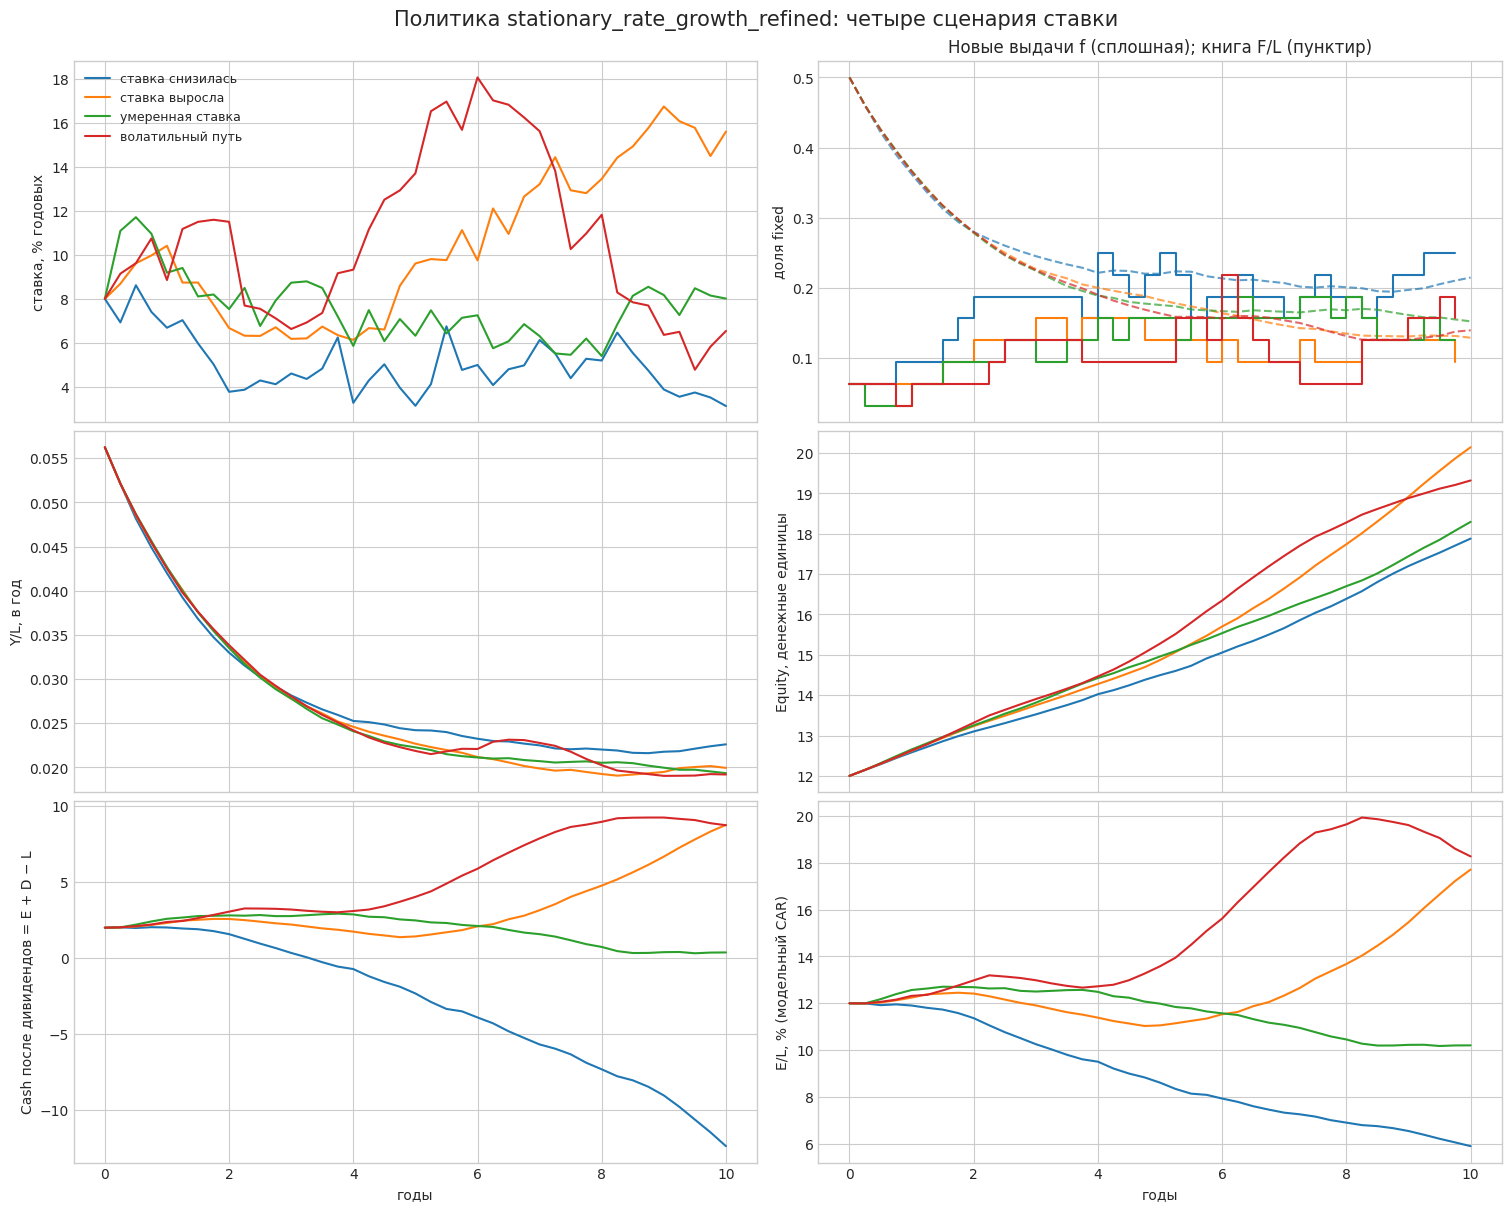

In [88]:
colors = dict(zip(chosen, plt.get_cmap("tab10").colors[:len(chosen)]))
fig, ax = plt.subplots(3, 2, figsize=(15, 12), sharex=True, constrained_layout=True)
for label, i in chosen.items():
    c = colors[label]
    ax[0, 0].plot(times, 100*states[:, i, 0], color=c, label=label)
    ax[0, 1].step(times[:-1], actions[:, i], where="post", color=c)
    loan_path = loan_paths[:, i]
    cash_path = states[:, i, 3] + deposit_paths[:, i] - loan_path
    ax[0, 1].plot(times, states[:, i, 1]/loan_path, color=c, ls="--", alpha=.7)
    ax[1, 0].plot(times, states[:, i, 2]/loan_path, color=c)
    ax[1, 1].plot(times, states[:, i, 3], color=c)
    ax[2, 0].plot(times, cash_path, color=c)
    ax[2, 1].plot(times, 100*states[:, i, 3]/loan_path, color=c)
ax[0, 0].set_ylabel("ставка, % годовых")
ax[0, 1].set_ylabel("доля fixed")
ax[0, 1].set_title("Новые выдачи f (сплошная); книга F/L (пунктир)")
ax[1, 0].set_ylabel("Y/L, в год")
ax[1, 1].set_ylabel("Equity, денежные единицы")
ax[2, 0].set_ylabel("Cash после дивидендов = E + D − L")
ax[2, 1].set_ylabel("E/L, % (модельный CAR)")
ax[0, 0].legend(loc="best", fontsize=9)
for a in ax[-1]: a.set_xlabel("годы")
fig.suptitle(f"Политика {RUN_ID}: четыре сценария ставки", fontsize=15)
plt.show()


## Денежная позиция и выплаченные дивиденды

Показанный Cash — **реальная денежная позиция модели после выплат**, $C_t=E_t+D_t-L_t$. Поток владельцу $B_t=\alpha\Pi_t$ уже вычтен из изменения капитала: $dE_t=(\Pi_t-B_t)dt$. Так как $L_t$ и $D_t$ растут, выполняется тождество

$$dC_t=[\Pi_t-B_t-g(L_t-D_t)]dt.$$

Первый член — оставленная в банке прибыль, второй — потребность в финансировании части роста кредитов, не покрытой новыми депозитами. Если они близки, Cash выходит на плато, даже когда абсолютный Equity растёт. При убытке $B_t<0$ означает взнос владельца. Накопленные выплаты ниже посчитаны по midpoint-ставкам потоков без дисконтирования; это **не** траектория Cash в альтернативном мире без дивидендов, поскольку изменение Cash там повлияло бы и на будущую прибыль.


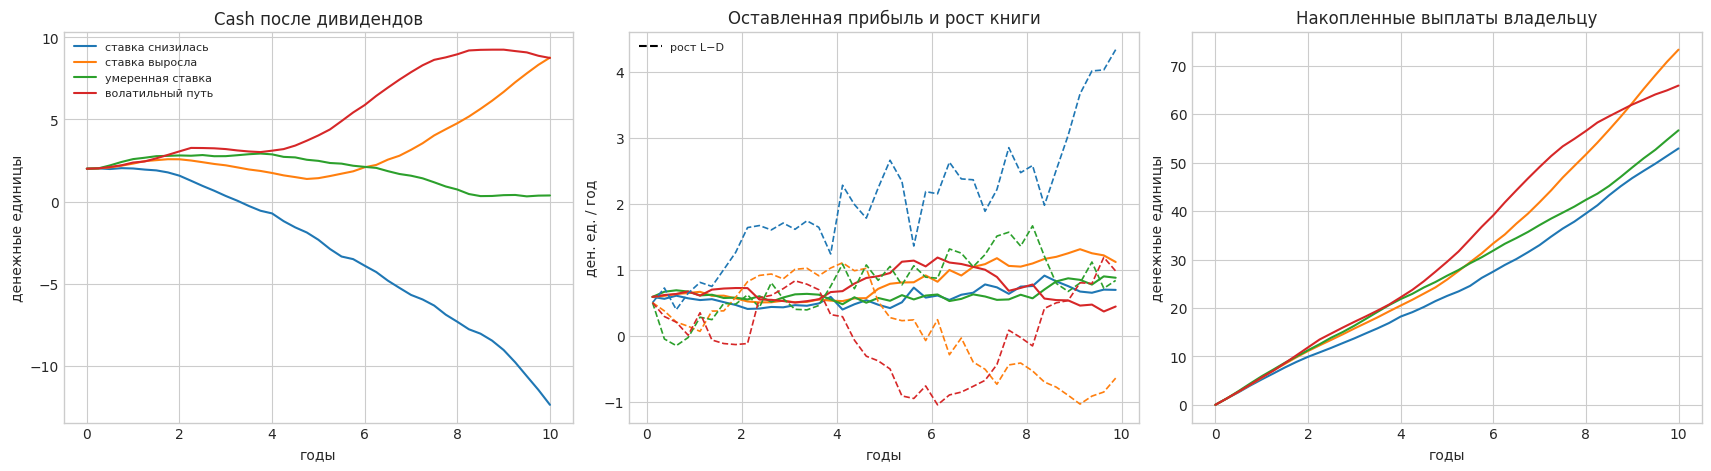

ставка снизилась       : E=17.88, L-D=30.26, Cash=-12.38, выплачено≈52.93, CAR=5.91%
ставка выросла         : E=20.15, L-D=11.38, Cash=8.77, выплачено≈73.32, CAR=17.70%
умеренная ставка       : E=18.30, L-D=17.92, Cash=0.37, выплачено≈56.67, CAR=10.21%
волатильный путь       : E=19.32, L-D=10.58, Cash=8.74, выплачено≈65.91, CAR=18.26%


In [89]:
cash_after_dividends = states[:, :, 3] + deposit_paths - loan_paths
retained_profit_rate = profit_mid - dividend_mid
growth_funding_rate = (loan_paths[1:]-loan_paths[:-1])/cfg.dt*(1-p.deposits/p.loans)
cumulative_dividends = np.concatenate((np.zeros((1, states.shape[1])),
    np.cumsum(dividend_mid*cfg.dt, axis=0)), axis=0)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), constrained_layout=True)
for label, i in chosen.items():
    color = colors[label]
    ax[0].plot(times, cash_after_dividends[:, i], color=color, label=label)
    ax[1].plot(times[:-1]+cfg.dt/2, retained_profit_rate[:, i], color=color)
    ax[2].plot(times, cumulative_dividends[:, i], color=color)
for label, i in chosen.items():
    ax[1].plot(times[:-1]+cfg.dt/2, growth_funding_rate[:, i], color=colors[label], ls='--', lw=1.2)
ax[1].plot([], [], color='black', ls='--', label='рост L−D')
ax[0].set(title='Cash после дивидендов', ylabel='денежные единицы')
ax[1].set(title='Оставленная прибыль и рост книги', ylabel='ден. ед. / год')
ax[2].set(title='Накопленные выплаты владельцу', ylabel='денежные единицы')
for a in ax: a.set_xlabel('годы')
ax[0].legend(fontsize=8)
ax[1].legend(fontsize=8)
plt.show()

for label, i in chosen.items():
    print(f'{label:23s}: E={states[-1,i,3]:.2f}, L-D={loan_paths[-1,i]-deposit_paths[-1,i]:.2f}, '
          f'Cash={cash_after_dividends[-1,i]:.2f}, '
          f'выплачено≈{cumulative_dividends[-1,i]:.2f}, '
          f'CAR={states[-1,i,3]/loan_paths[-1,i]:.2%}')


## Поток NII, реализованный NII за следующий год и MtM

Ниже $n(X_t)$ — годовой темп чистого процентного дохода, а $NII_{1y}^{\mathrm{real}}(t)$ — сумма процентных доходов и расходов за *следующий* год выбранного пути. Интеграл считается тем же midpoint-приближением, которое использует шаг среды. Это **не** бухгалтерская прибыль: операционные расходы вычтены из `profit`, но не из NII; дивиденды также не вычитаются из NII. MtM переоценивает уже сформированную книгу в момент $t$ и не добавляет будущую прибыль от новых выдач.

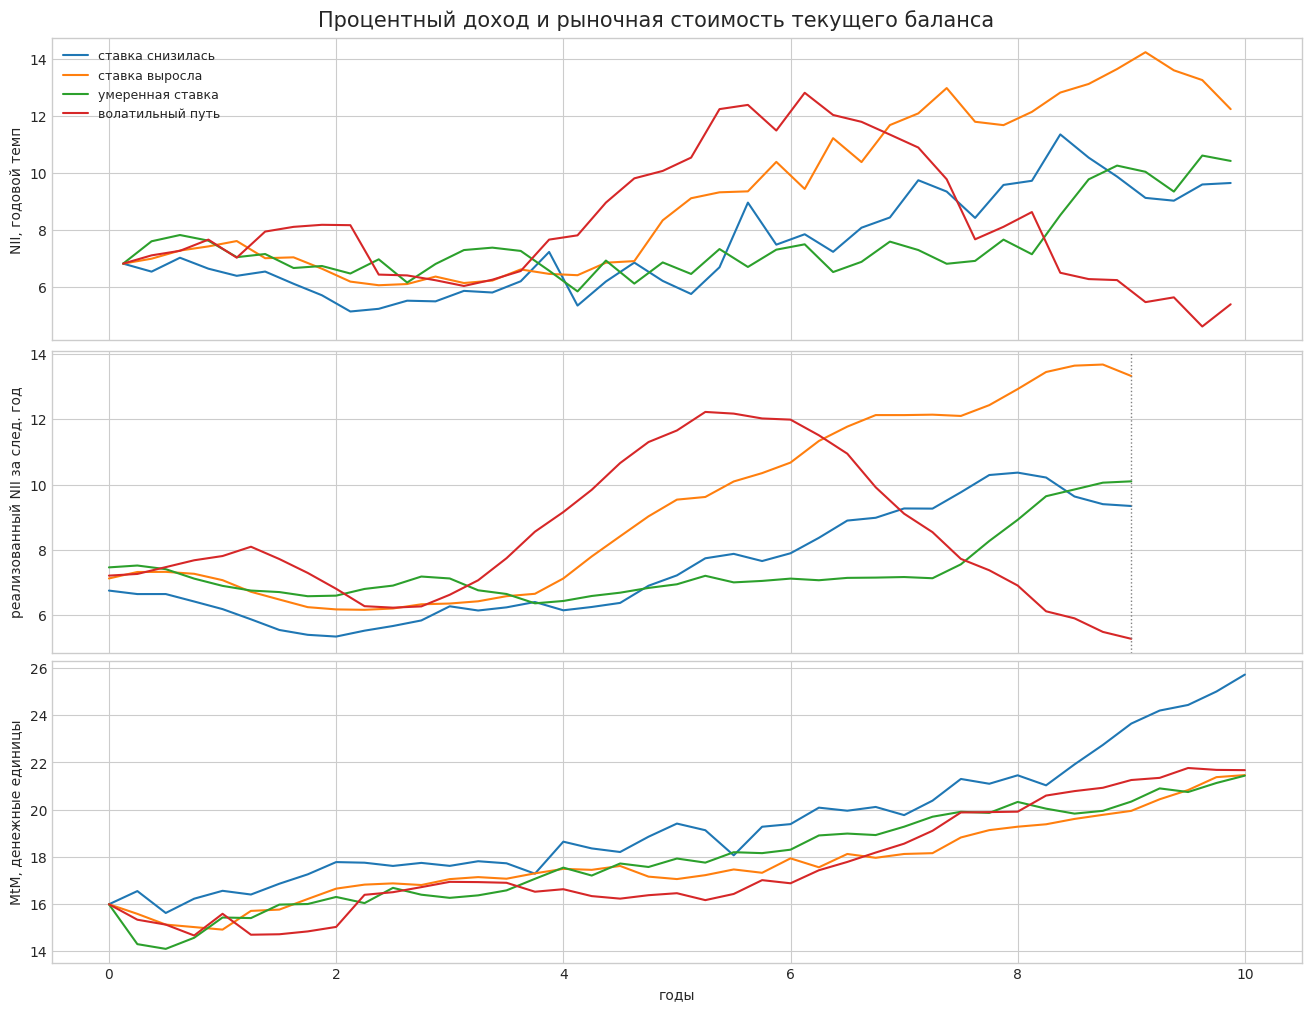

In [90]:
# Реализованный годовой NII по будущему отрезку пути; интерполяция к t+1
# работает и тогда, когда один год не кратен шагу сетки.
nii_cum = np.concatenate([np.zeros((1, N_PATHS)), np.cumsum(nii_mid * cfg.dt, axis=0)])
valid = times + 1 <= cfg.horizon + 1e-10
nii_1y = np.full((cfg.steps+1, N_PATHS), np.nan)
for j in np.flatnonzero(valid):
    for i in chosen.values():
        nii_1y[j, i] = np.interp(times[j] + 1, times, nii_cum[:, i]) - nii_cum[j, i]

with torch.no_grad():
    mtm = np.stack([
        env.terminal_value(torch.as_tensor(states[k], device=DEVICE, dtype=dtype), time=times[k], loans=torch.as_tensor(loan_paths[k], device=DEVICE, dtype=dtype)).cpu().numpy()
        for k in range(cfg.steps+1)
    ])

fig, ax = plt.subplots(3, 1, figsize=(13, 10), sharex=True, constrained_layout=True)
for label, i in chosen.items():
    c = colors[label]
    ax[0].plot(times[:-1]+cfg.dt/2, nii_mid[:, i], color=c, label=label)
    ax[1].plot(times[valid], nii_1y[valid, i], color=c)
    ax[2].plot(times, mtm[:, i], color=c)
ax[0].set_ylabel("NII, годовой темп")
ax[1].set_ylabel("реализованный NII за след. год")
ax[2].set_ylabel("MtM, денежные единицы")
ax[2].set_xlabel("годы")
ax[0].legend(loc="best", fontsize=9)
ax[1].axvline(cfg.horizon-1, color="gray", ls=":", lw=1)
fig.suptitle("Процентный доход и рыночная стоимость текущего баланса", fontsize=15)
plt.show()


## IRRBB-метрика: замороженный баланс и шок +100 б.п.

Для $\Delta NII_{1y}$ в каждой точке траектории фиксируем $F,Y,E,L_t,D_t$ и $C=E+D_t-L_t$ на весь следующий год: нет погашений, новых выдач и применения политики. Базовая ставка равна текущей $r$, шоковая — $r+\varepsilon$, $\varepsilon=0.01$; обе постоянны в течение этого года. Floating-кредиты, cash и депозиты немедленно переоцениваются по соответствующим правилам модели, fixed-купоны остаются прежними. Поэтому $NII_{1y}^0=n(t,x)\cdot1$, а

$$\Delta NII_{1y}^{+100}=0.01\,[L_t-F+C-\beta D_t]\cdot1\text{ год}.$$

Для MtM в тот же момент меняем короткую ставку на $r+0.01$ и переоцениваем текущую книгу по $Q$, не изменяя $F,Y,E$. Это шок **состояния короткой ставки CIR**, а не параллельный сдвиг всех сроков кривой доходности. Денежный поток float считается немедленно пересмотренным.


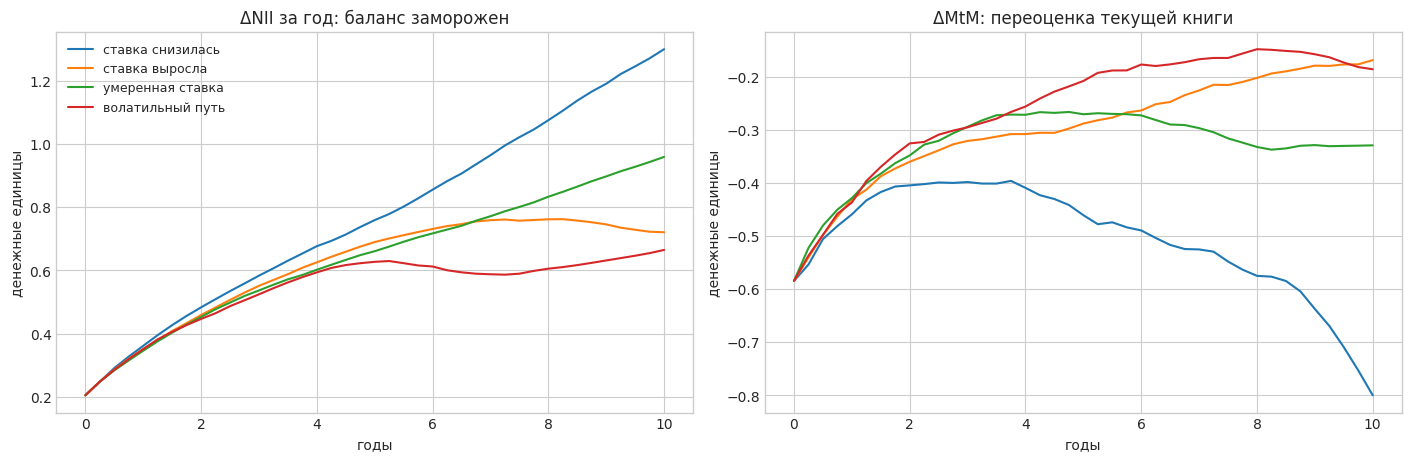

In [91]:
shock = 0.01
delta_nii = shock * (states[:, :, 3] - states[:, :, 1] + (1-p.deposit_beta)*deposit_paths)
with torch.no_grad():
    shocked = np.stack([
        env.terminal_value(torch.as_tensor(states[k], device=DEVICE, dtype=dtype)
                           + torch.tensor([shock, 0, 0, 0], device=DEVICE, dtype=dtype), time=times[k], loans=torch.as_tensor(loan_paths[k], device=DEVICE, dtype=dtype)).cpu().numpy()
        for k in range(cfg.steps+1)
    ])
delta_mtm = shocked - mtm
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True, constrained_layout=True)
for label, i in chosen.items():
    ax[0].plot(times, delta_nii[:, i], color=colors[label], label=label)
    ax[1].plot(times, delta_mtm[:, i], color=colors[label])
ax[0].set_title('ΔNII за год: баланс заморожен')
ax[1].set_title('ΔMtM: переоценка текущей книги')
for a in ax: a.set_xlabel('годы'); a.set_ylabel('денежные единицы')
ax[0].legend(fontsize=9)
plt.show()


### Производные метрик по короткой ставке

При фиксированных $F,Y,E,L,D$ имеем $\partial_r NII_{1y}=L-F+C-\beta D$ и $\partial_{rr}NII_{1y}=0$: формула для $\Delta NII_{1y}$ точна при любом постоянном сдвиге. Для $\operatorname{MtM}=E-F+(Y+\mu F)A_\mu^Q(r)$: $\partial_r\operatorname{MtM}=(Y+\mu F)(A_\mu^Q)'(r)\le0$, $\partial_{rr}\operatorname{MtM}=(Y+\mu F)(A_\mu^Q)''(r)\ge0$. При CIR $P_Q(r,u)=a_Q(u)e^{-B_Q(u)r}$, так что производные аннуитета получаются интегрированием $-B_QP_Q$ и $B_Q^2P_Q$ соответственно. Ниже проверяем чувствительности и точный шок в начальной точке; полный вывод приведён в `model_formulation.tex`.

In [92]:
r0, F0, Y0, E0 = report['reference_state']
r_tensor = torch.tensor(r0, device=DEVICE, dtype=torch.float64, requires_grad=True)
annuity = env.annuity_q(r_tensor)
annuity_r = torch.autograd.grad(annuity, r_tensor, create_graph=True)[0]
annuity_rr = torch.autograd.grad(annuity_r, r_tensor)[0]
nii_r = p.loans - F0 + E0 + p.deposits - p.loans - p.deposit_beta*p.deposits
mtm_r = (Y0 + p.amortization*F0) * annuity_r.item()
mtm_rr = (Y0 + p.amortization*F0) * annuity_rr.item()
print(f'∂NII_1y/∂r = {nii_r:.4f}; ΔNII(+100bp) = {shock*nii_r:.4f}')
print(f'∂MtM/∂r = {mtm_r:.4f}; ∂²MtM/∂r² = {mtm_rr:.4f}')
print(f'ΔMtM(+100bp): exact = {delta_mtm[0, 0]:.4f}, '
      f'linear = {shock*mtm_r:.4f}, quadratic = {shock*mtm_r + .5*shock**2*mtm_rr:.4f}')


∂NII_1y/∂r = 20.5000; ΔNII(+100bp) = 0.2050
∂MtM/∂r = -58.8513; ∂²MtM/∂r² = 82.7357
ΔMtM(+100bp): exact = -0.5844, linear = -0.5885, quadratic = -0.5844


## Три метрики при одинаковом шоке ставки

В каждом достигнутом состоянии $x=(r,F,Y,E)$ сравниваем шок $+100$ б.п.: $\Delta NII_{1y}$ при замороженном балансе, $\Delta\mathrm{MtM}$ при переоценке текущей книги и $\Delta V=V(t,r+0.01,F,Y,E)-V(t,r,F,Y,E)$. Обе оценки $V$ берутся из одного чекпоинта; после шока будущая политика может измениться. В конечногоризонтной модели $V(T,x)=\mathrm{MtM}(x)$. В стационарной модели такого равенства нет: конец графика — только конец визуализации.

Все три величины имеют денежные единицы, но разные горизонты и соглашения. $V$ — приближение из обученной сети; смотрите диагностику невязки в отчёте.

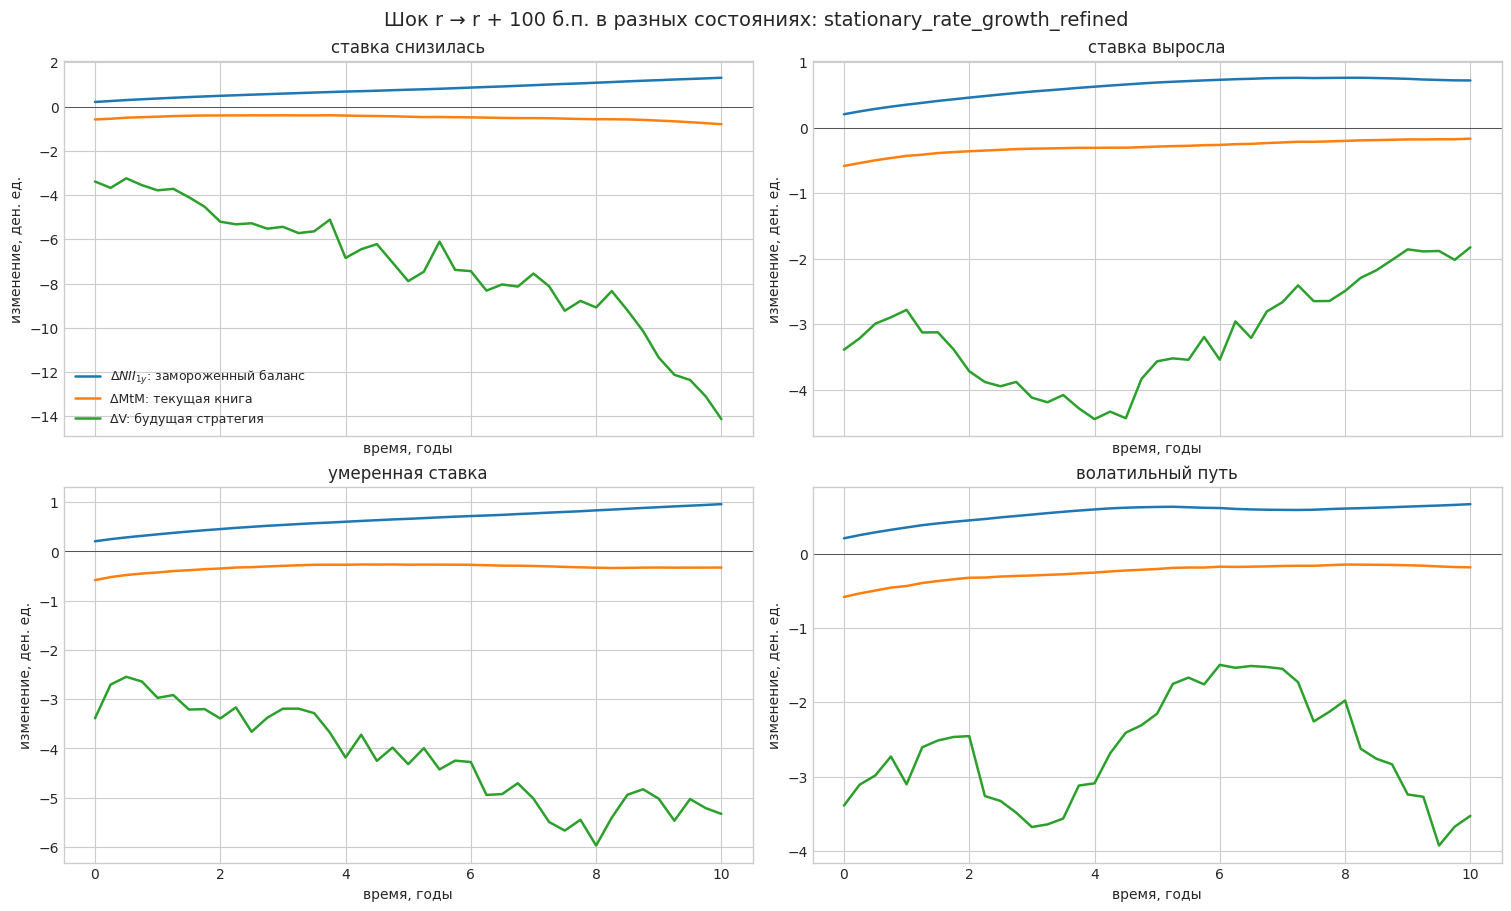

Сценарий                  t      ΔNII_1y       ΔMtM          ΔV
ставка снизилась         0.00       0.2050      -0.5844      -3.3901
ставка снизилась         1.00       0.3614      -0.4591      -3.7888
ставка снизилась         5.00       0.7591      -0.4606      -7.8929
ставка снизилась         9.00       1.1904      -0.6373     -11.3472
ставка снизилась        10.00       1.2997      -0.7999     -14.1298
ставка выросла           0.00       0.2050      -0.5844      -3.3901
ставка выросла           1.00       0.3513      -0.4306      -2.7810
ставка выросла           5.00       0.6897      -0.2881      -3.5664
ставка выросла           9.00       0.7456      -0.1790      -1.8578
ставка выросла          10.00       0.7207      -0.1686      -1.8266
умеренная ставка         0.00       0.2050      -0.5844      -3.3901
умеренная ставка         1.00       0.3460      -0.4285      -2.9749
умеренная ставка         5.00       0.6608      -0.2705      -4.3208
умеренная ставка         9.00       0.8

In [93]:
@torch.no_grad()
def compute_delta_v(state_paths, rate_shock=shock):
    bump = torch.tensor([rate_shock, 0, 0, 0], device=DEVICE, dtype=dtype)
    changes = []
    for layer in range(cfg.steps + 1):
        x = torch.as_tensor(state_paths[layer], device=DEVICE, dtype=dtype)
        kwargs = {"loans": torch.as_tensor(loan_paths[layer], device=DEVICE, dtype=dtype)} if STATIONARY_MODE else {}
        changes.append((solution.value(layer, x+bump, **kwargs)-solution.value(layer, x, **kwargs)).cpu().numpy())
    return np.stack(changes)

delta_v = compute_delta_v(states)
if not STATIONARY_MODE:
    assert np.allclose(delta_v[-1], delta_mtm[-1], atol=2e-4), 'At T, V must equal MtM'

fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True, constrained_layout=True)
for axis, (label, i) in zip(axes.flat, chosen.items()):
    axis.plot(times, delta_nii[:, i], label=r'$\Delta NII_{1y}$: замороженный баланс', lw=1.8)
    axis.plot(times, delta_mtm[:, i], label='ΔMtM: текущая книга', lw=1.8)
    axis.plot(times, delta_v[:, i], label='ΔV: будущая стратегия', lw=1.8)
    axis.axhline(0, color='black', lw=.7, alpha=.6)
    axis.set(title=label, xlabel='время, годы', ylabel='изменение, ден. ед.')
axes.flat[0].legend(fontsize=9)
fig.suptitle(f'Шок r → r + 100 б.п. в разных состояниях: {RUN_ID}', fontsize=14)
plt.show()

print('Сценарий                  t      ΔNII_1y       ΔMtM          ΔV')
for label, i in chosen.items():
    for target_time in (0, 1, cfg.horizon/2, cfg.horizon-1, cfg.horizon):
        k = int(np.argmin(np.abs(times-target_time)))
        print(f'{label:23s} {times[k]:5.2f} {delta_nii[k,i]:12.4f} '
              f'{delta_mtm[k,i]:12.4f} {delta_v[k,i]:12.4f}')


## Сценарный анализ в заданных состояниях

Следующий анализ **не использует траектории выученной политики**. Мы вручную задаём несколько контрфактических состояний одной книги размера $L_0$ и считаем в каждом один и тот же шок $r\mapsto r+100$ б.п. Таблица и столбцы показывают $\Delta NII_{1y}$ при замороженном балансе, $\Delta\mathrm{MtM}$ текущей книги и $\Delta V$ с последующей оптимальной политикой из чекпоинта. Все значения приведены к $L_0$ только для удобства сравнения масштаба; расчёт самих дельт выполнен в денежных единицах.

«Исходная книга» — это смешанный портфель из `reference_state` сохранённого чекпоинта (его фактическая доля fixed показана в подписи). Она служит контрольным состоянием для сравнения с остальными сценариями. Из её $Y$ мы восстанавливаем условные купон старых fixed и спред старых float. Это **интерпретация агрегированного состояния**, а не наблюдаемая история договоров. Для сценариев «другая ставка» сохраняем $F,Y,E$: старые договоры не переписываются вслед за текущей ставкой. Для сценариев «другая доля fixed» сохраняем $L,D,E$ и старые ставки *на единицу каждого вида кредита*, а $Y$ пересчитываем для нового состава книги. Дополнительно рассматриваем дорогой fixed-винтаж, пониженный капитал и крайние составы книги: 100% float и 100% fixed. В крайних сценариях текущие ставки старых договоров оставлены такими же, как в исходной книге; это сравнение состава при прочих равных, а не реконструкция истории выдач. Это возможные состояния для оценки функции $V$, а не мгновенные сделки и не новые обученные модели.


Ставки старых договоров в исходной книге: fixed-купон=10.25%, float-спред=1.00%; шок=+100 б.п.
Сценарий                              r    F/L    E/L    Cash/L  ΔNII_1y     ΔMtM       ΔV     (ден. ед.)
Исходная книга: 50% fixed             8.0% 50.0% 12.0%    2.0%     +0.205     -0.584     -3.390
Низкая ставка, те же договоры         2.0% 50.0% 12.0%    2.0%     +0.205     -0.636     -5.687
Высокая ставка, те же договоры       14.0% 50.0% 12.0%    2.0%     +0.205     -0.537     -2.219
20% fixed в книге                     8.0% 20.0% 12.0%    2.0%     +0.505     -0.249     -3.044
80% fixed в книге                     8.0% 80.0% 12.0%    2.0%     -0.095     -0.919     -3.736
Низкая ставка + дорогой fixed         2.0% 80.0% 12.0%    2.0%     -0.095     -1.046     -6.159
Пониженный капитал                    8.0% 50.0% 10.5%    0.5%     +0.190     -0.584     -3.390
Вся книга — float (0% fixed)          8.0%  0.0% 12.0%    2.0%     +0.705     -0.026     -2.807
Вся книга — fixed (100% fixed) 

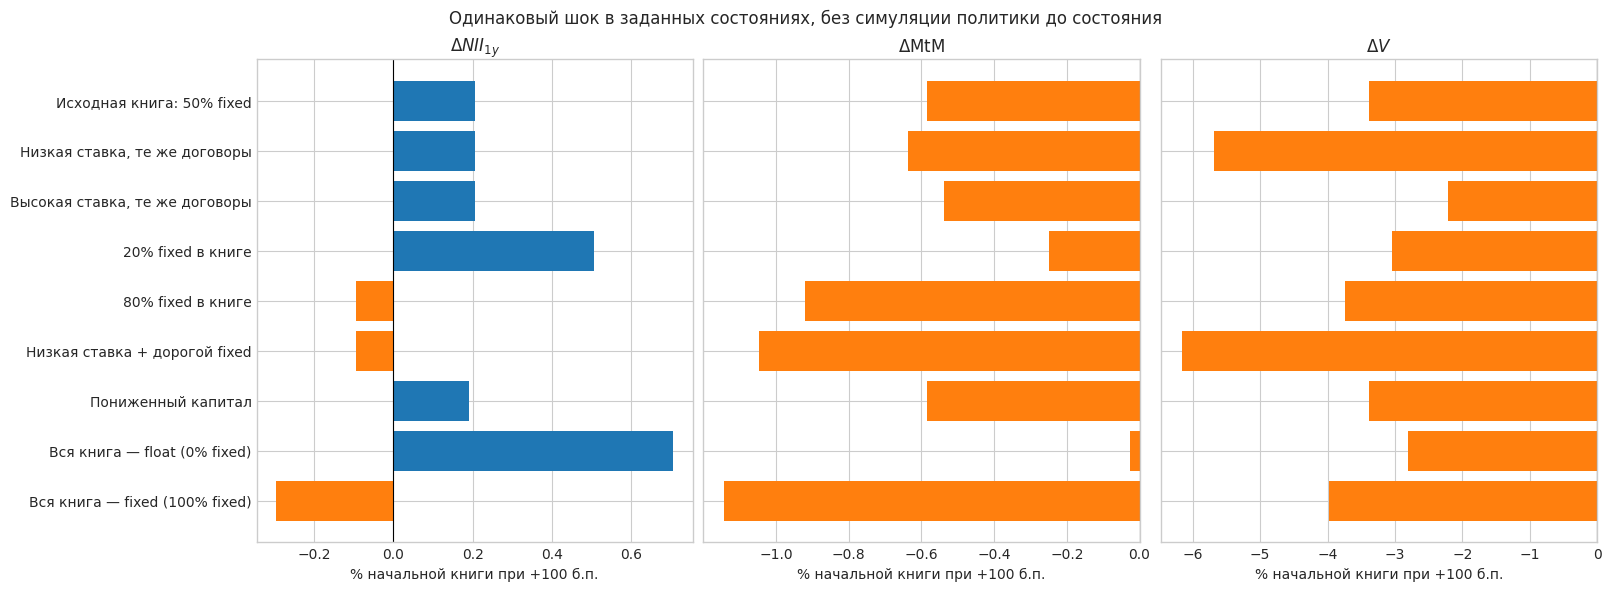

In [94]:
SCENARIO_SHOCK = 0.01
L_SC = env.loans_at(0.0)
D_SC = env.deposits_at(0.0)
r_ref, F_ref, Y_ref, E_ref = map(float, report['reference_state'])
a_ref, e_ref = F_ref/L_SC, E_ref/L_SC
old_float_spread = p.floating_spread_0 - p.floating_demand_slope*(1-a_ref)
old_fixed_coupon = ((Y_ref-old_float_spread*(L_SC-F_ref))/F_ref
                    if F_ref > 1e-8 else float(env.new_fixed_coupon(
                        torch.tensor(r_ref, device=DEVICE, dtype=dtype))))
assert old_float_spread >= 0 and old_fixed_coupon >= 0

# Каждая строка — отдельное состояние при t=0, без предшествующей симуляции.
scenario_specs = [
    (f'Исходная книга: {a_ref:.0%} fixed', r_ref, a_ref, e_ref, old_fixed_coupon),
    ('Низкая ставка, те же договоры', max(.02, r_ref-.06), a_ref, e_ref, old_fixed_coupon),
    ('Высокая ставка, те же договоры', r_ref+.06, a_ref, e_ref, old_fixed_coupon),
    ('20% fixed в книге', r_ref, .20, e_ref, old_fixed_coupon),
    ('80% fixed в книге', r_ref, .80, e_ref, old_fixed_coupon),
    ('Низкая ставка + дорогой fixed', max(.02, r_ref-.06), .80, e_ref,
     old_fixed_coupon+.02),
    ('Пониженный капитал', r_ref, a_ref, max(.105, e_ref-.02), old_fixed_coupon),
    ('Вся книга — float (0% fixed)', r_ref, .0, e_ref, old_fixed_coupon),
    ('Вся книга — fixed (100% fixed)', r_ref, 1.0, e_ref, old_fixed_coupon),
]

def make_scenario_states(specs):
    rows = []
    for _, rate, fixed_share, capital_share, fixed_coupon in specs:
        fixed = L_SC*fixed_share
        locked_income = fixed*fixed_coupon + (L_SC-fixed)*old_float_spread
        rows.append((rate, fixed, locked_income, L_SC*capital_share))
    return torch.tensor(rows, device=DEVICE, dtype=dtype)

@torch.no_grad()
def scenario_risk_metrics(x):
    """Money-unit deltas at t=0; works for either checkpoint type."""
    original_shape = x.shape[:-1]
    pieces = []
    bump = torch.tensor([SCENARIO_SHOCK, 0, 0, 0], device=DEVICE, dtype=dtype)
    for batch in x.reshape(-1, 4).split(256):
        r, F, Y, E = batch.unbind(-1)
        d_nii = SCENARIO_SHOCK*(E-F+(1-p.deposit_beta)*D_SC)
        d_mtm = (Y+p.amortization*F)*(
            env.annuity_q(r+SCENARIO_SHOCK)-env.annuity_q(r))
        d_value = solution.value(0, batch+bump)-solution.value(0, batch)
        pieces.append(torch.stack((d_nii, d_mtm, d_value), dim=-1).cpu())
    return torch.cat(pieces).reshape(*original_shape, 3).numpy()

scenario_states = make_scenario_states(scenario_specs)
scenario_deltas = scenario_risk_metrics(scenario_states)
metric_names = (r'$\Delta NII_{1y}$', r'$\Delta\mathrm{MtM}$', r'$\Delta V$')
print(f'Ставки старых договоров в исходной книге: fixed-купон={old_fixed_coupon:.2%}, '
      f'float-спред={old_float_spread:.2%}; шок=+100 б.п.')
print('Сценарий                              r    F/L    E/L    Cash/L  '
      'ΔNII_1y     ΔMtM       ΔV     (ден. ед.)')
for spec, row, delta in zip(scenario_specs, scenario_states.cpu().numpy(), scenario_deltas):
    cash_share = row[3]/L_SC + D_SC/L_SC - 1
    print(f'{spec[0]:36s} {row[0]:5.1%} {row[1]/L_SC:5.1%} '
          f'{row[3]/L_SC:5.1%} {cash_share:7.1%} '
          f'{delta[0]:+10.3f} {delta[1]:+10.3f} {delta[2]:+10.3f}')

fig, axes = plt.subplots(1, 3, figsize=(16, 5.8), sharey=True, constrained_layout=True)
labels = [item[0] for item in scenario_specs]
y_pos = np.arange(len(labels))
for j, ax in enumerate(axes):
    values = 100*scenario_deltas[:, j]/L_SC
    ax.barh(y_pos, values, color=np.where(values >= 0, 'tab:blue', 'tab:orange'))
    ax.axvline(0, color='black', lw=.8)
    ax.set(title=metric_names[j], xlabel='% начальной книги при +100 б.п.')
axes[0].set_yticks(y_pos, labels)
axes[0].invert_yaxis()
fig.suptitle('Одинаковый шок в заданных состояниях, без симуляции политики до состояния')
plt.show()


### Разложение шоковых метрик на денежные потоки

Для каждого заданного состояния чувствительность **замороженного** баланса к шоку $\delta=+100$ б.п. распадается на три вклада:

$$\Delta NII_{1y}=\delta\underbrace{(L-F)}_{\text{float-кредиты}}+\delta\underbrace{C}_{\text{Cash}}-\delta\underbrace{\beta D}_{\text{депозиты}},\qquad C=E+D-L.$$

Плавающие кредиты дают положительный вклад, Cash — вклад со знаком самого Cash, а повышение стоимости депозитов — отрицательный. Будущая выдача здесь не учитывается.

Для переоценки действующих договоров положим $\Delta A_Q=A_Q(r+\delta)-A_Q(r)<0$. Тогда

$$\Delta\mathrm{MtM}=\underbrace{F k_{F,\mathrm{old}}\Delta A_Q}_{\text{купоны старых fixed}}+\underbrace{(L-F)s_{V,\mathrm{old}}\Delta A_Q}_{\text{спреды старых float}}+\underbrace{\mu F\Delta A_Q}_{\text{погашение fixed-основной суммы}}.$$

В крайних сценариях старые купон и спред условно сохранены на уровне исходной книги. Цветные полосы показывают отдельные вклады; чёрный ромб — их сумму. Масштаб — проценты от начальной книги $L_0$.


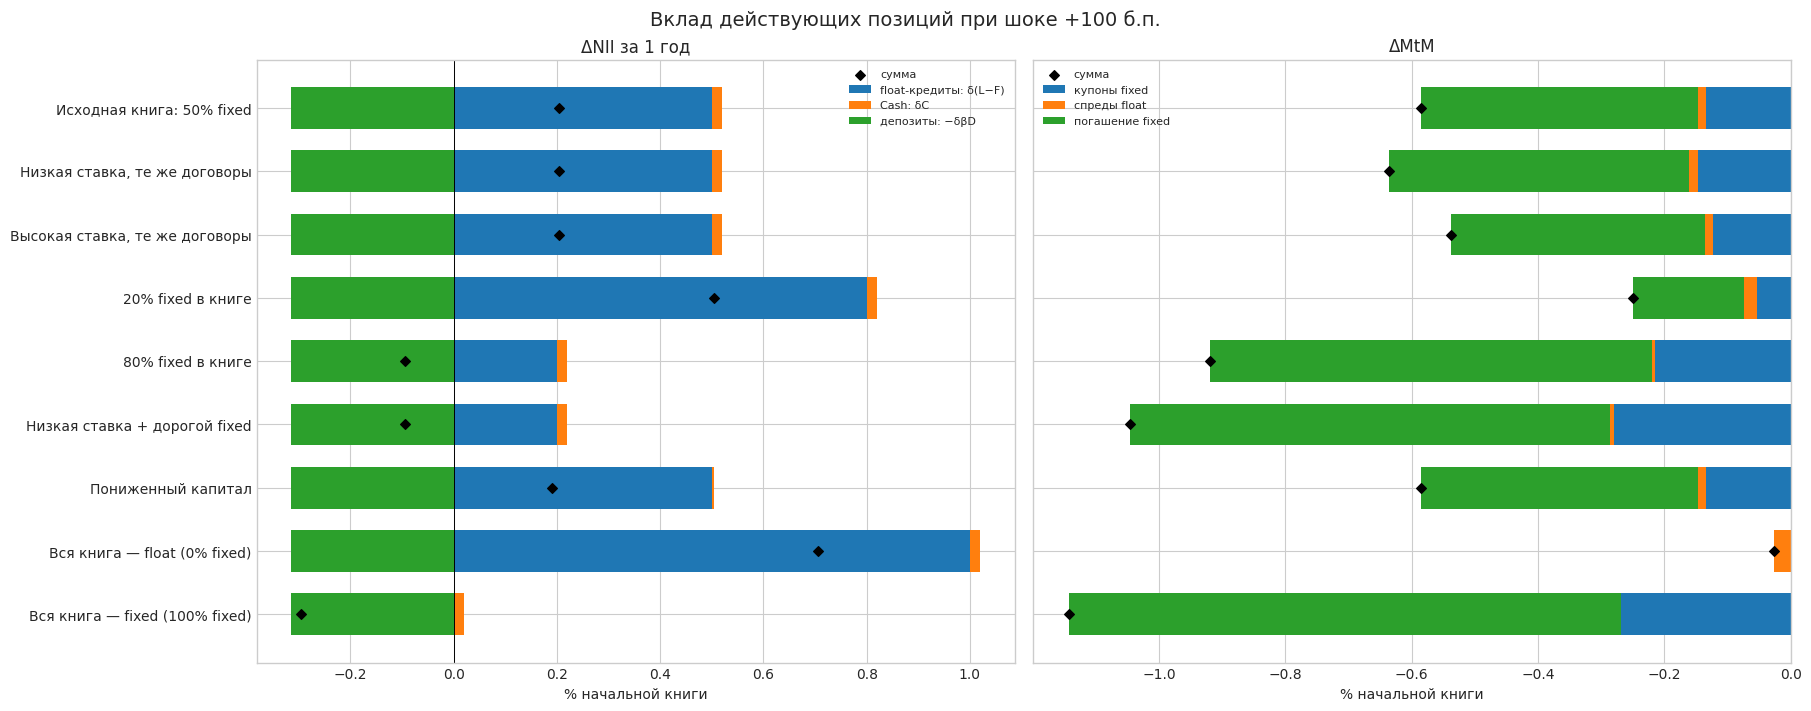

In [95]:
# Те же состояния и тот же шок, что на сценарной диаграмме выше.
with torch.no_grad():
    rates = scenario_states[:, 0]
    fixed = scenario_states[:, 1]
    cash = scenario_states[:, 3] + D_SC - L_SC
    delta_annuity = env.annuity_q(rates + SCENARIO_SHOCK) - env.annuity_q(rates)
    old_coupons = torch.tensor([spec[4] for spec in scenario_specs], device=DEVICE, dtype=dtype)
    nii_parts = torch.stack((
        SCENARIO_SHOCK*(L_SC-fixed), SCENARIO_SHOCK*cash,
        -SCENARIO_SHOCK*p.deposit_beta*torch.full_like(rates, D_SC)), -1).cpu().numpy()
    mtm_parts = torch.stack((
        fixed*old_coupons*delta_annuity,
        (L_SC-fixed)*old_float_spread*delta_annuity,
        p.amortization*fixed*delta_annuity), -1).cpu().numpy()
np.testing.assert_allclose(nii_parts.sum(1), scenario_deltas[:, 0], atol=2e-5)
np.testing.assert_allclose(mtm_parts.sum(1), scenario_deltas[:, 1], atol=2e-5)

fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=True, constrained_layout=True)
component_sets = (
    (nii_parts, scenario_deltas[:, 0], ('float-кредиты: δ(L−F)', 'Cash: δC',
      'депозиты: −δβD'), 'ΔNII за 1 год'),
    (mtm_parts, scenario_deltas[:, 1], ('купоны fixed', 'спреды float',
      'погашение fixed'), 'ΔMtM'),
)
y_positions = np.arange(len(scenario_specs))
for ax, (parts, totals, labels, title) in zip(axes, component_sets):
    positive = np.zeros(len(parts))
    negative = np.zeros(len(parts))
    for j, (label, color) in enumerate(zip(labels, ('tab:blue','tab:orange','tab:green'))):
        values = 100*parts[:, j]/L_SC
        left = np.where(values >= 0, positive, negative)
        ax.barh(y_positions, values, left=left, color=color, label=label, height=.66)
        positive += np.maximum(values, 0)
        negative += np.minimum(values, 0)
    ax.scatter(100*totals/L_SC, y_positions, color='black', marker='D',
               s=24, zorder=4, label='сумма')
    ax.axvline(0, color='black', lw=.7)
    ax.set(xlabel='% начальной книги', title=title)
    ax.legend(fontsize=8)
axes[0].set_yticks(y_positions, [spec[0] for spec in scenario_specs])
axes[0].invert_yaxis()
fig.suptitle('Вклад действующих позиций при шоке +100 б.п.', fontsize=14)
plt.show()


### Чувствительность метрик внутри каждого сценария

Слева меняем **существующую** долю fixed $F/L$ при той же ставке и том же капитале. Старый fixed-купон и старый float-спред данного сценария сохраняются, поэтому $Y=F k_{F,\mathrm{old}}+(L-F)s_{V,\mathrm{old}}$ пересчитывается. Справа меняем только текущую ставку, сохраняя $F,Y,E$. Вертикальная пунктирная линия отмечает исходную точку строки. Во всех точках к показанной ставке добавляется отдельный шок **+100 б.п.**; горизонтальная линия показывает нулевой эффект. Графики показывают чувствительность *метрик*, не долю новых fixed-выдач $f$.


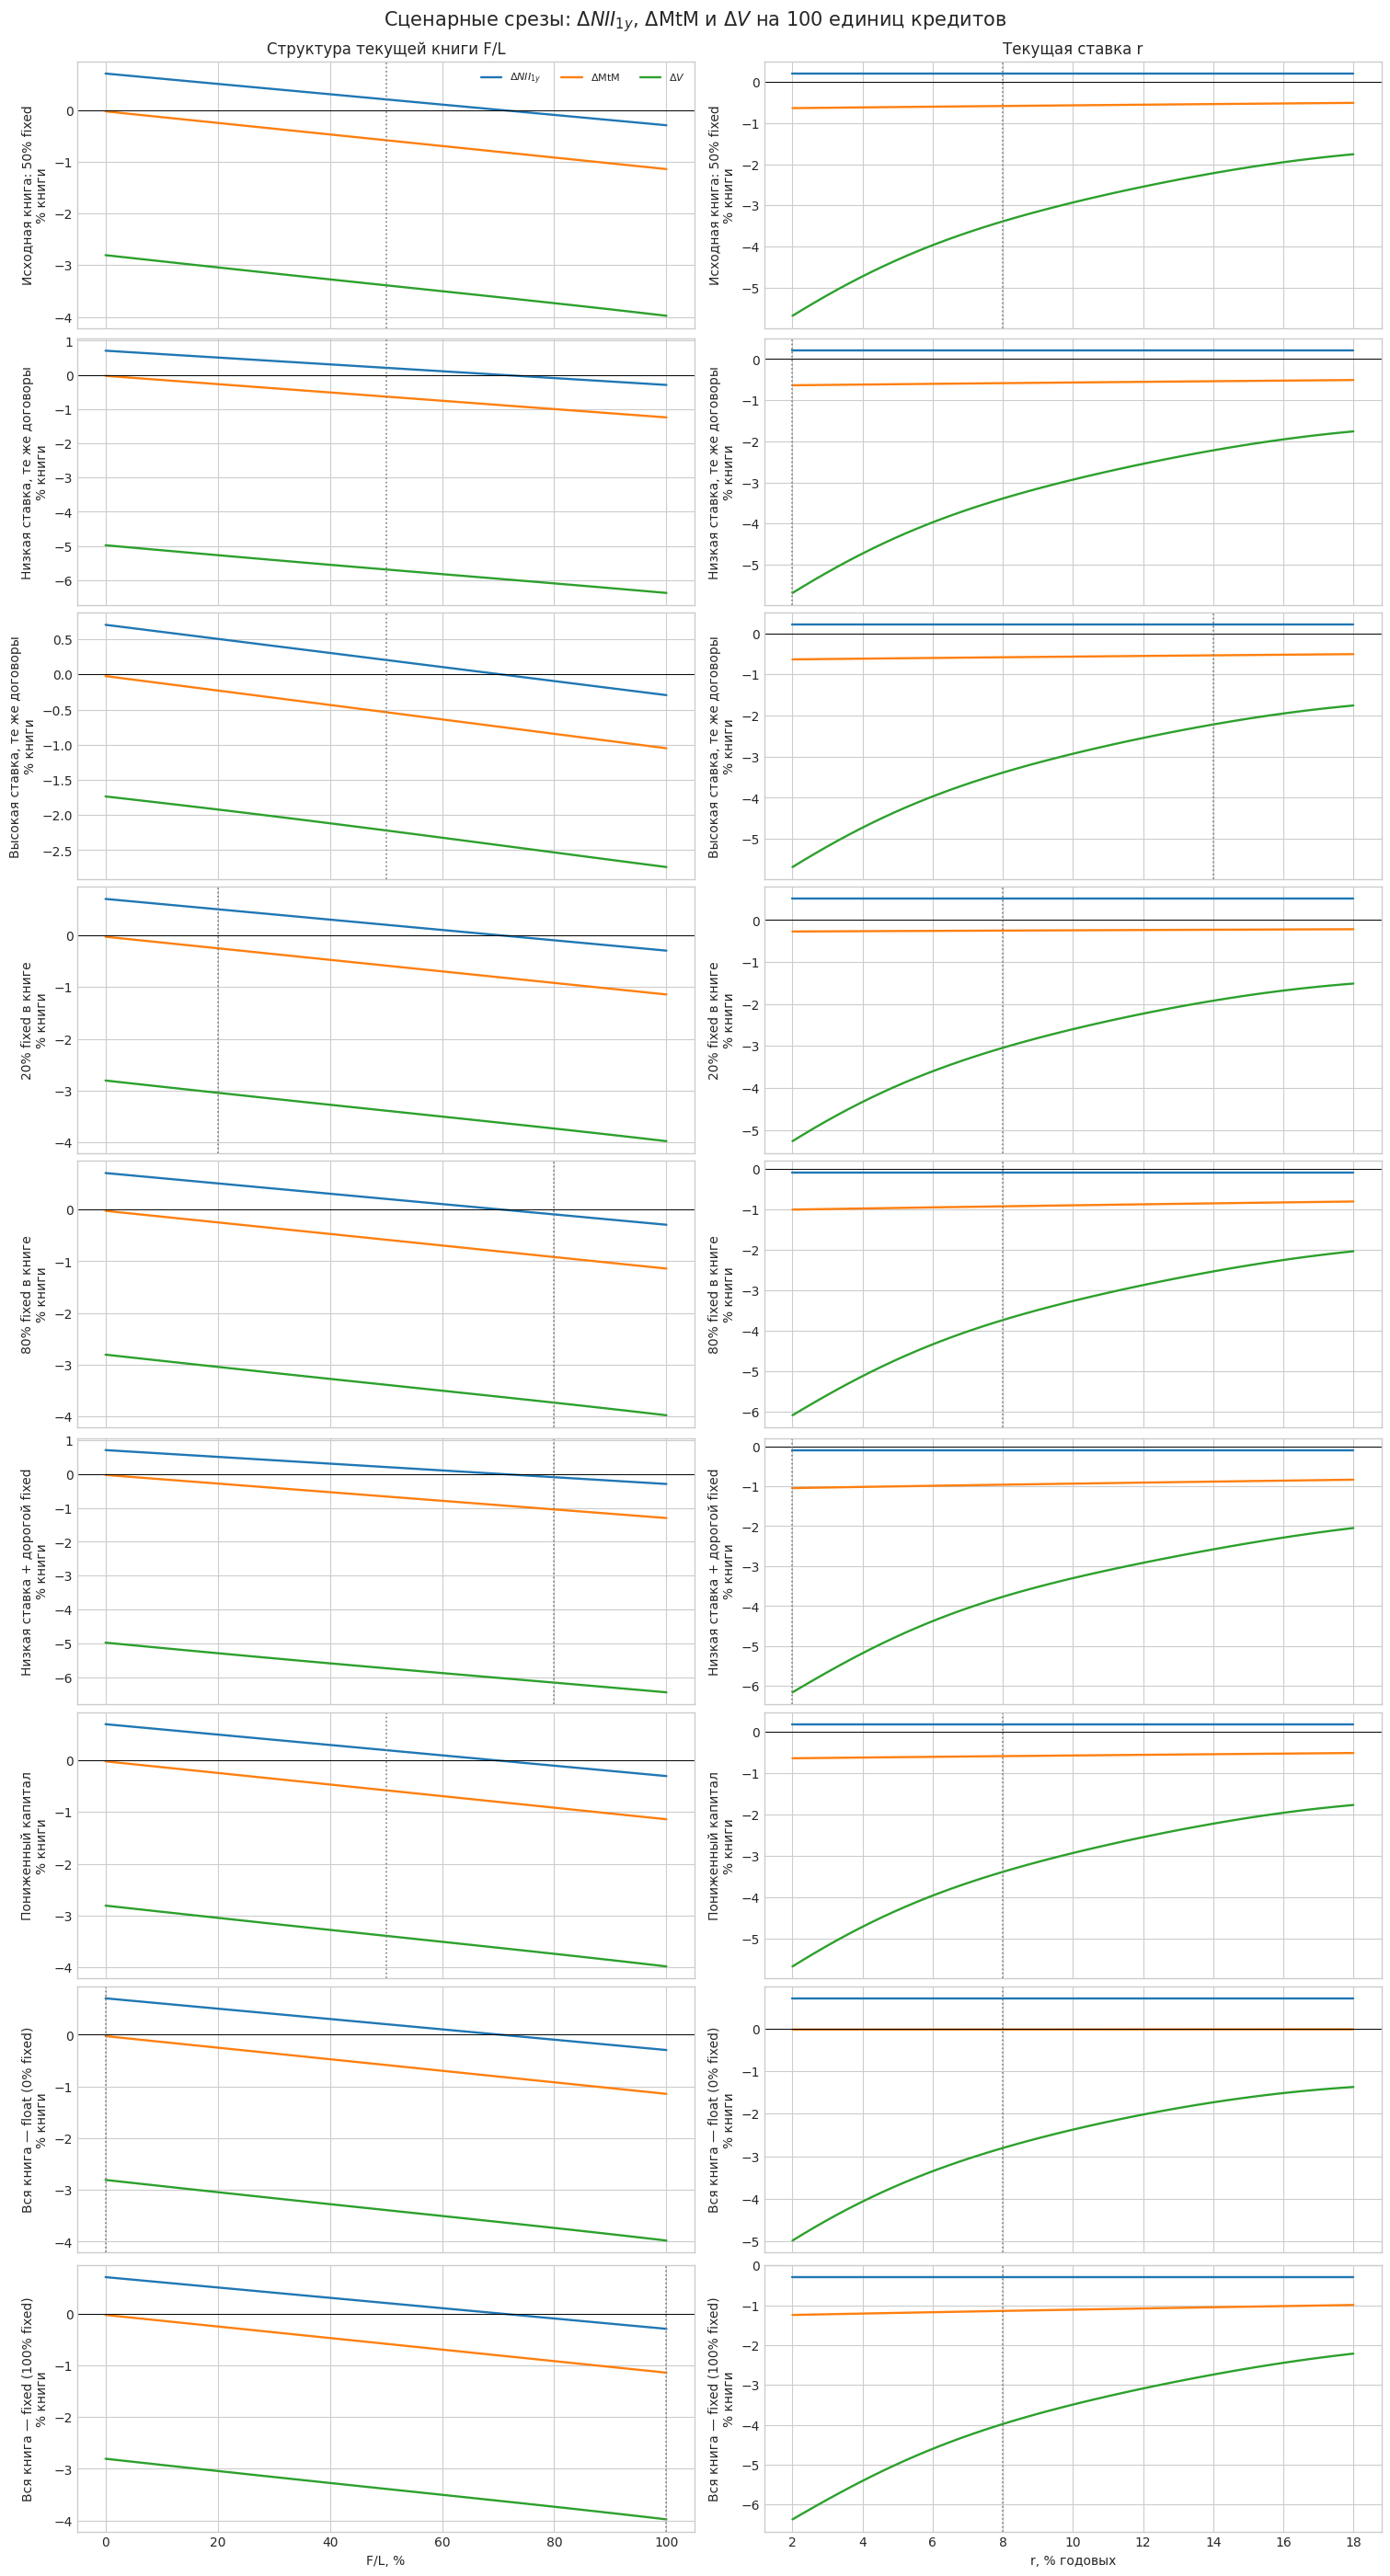

In [96]:
SCENARIO_CURVE_POINTS = 17 if os.environ.get('IRRBB_NOTEBOOK_SMOKE') else 51
scenario_share_grid = np.linspace(.0, 1.0, SCENARIO_CURVE_POINTS)
scenario_rate_grid = np.linspace(.02, .18, SCENARIO_CURVE_POINTS)
scenario_colors = ('tab:blue', 'tab:orange', 'tab:green')
fig, axes = plt.subplots(len(scenario_specs), 2,
                         figsize=(15, 3.1*len(scenario_specs)),
                         sharex='col', constrained_layout=True)
for row_idx, spec in enumerate(scenario_specs):
    label, rate, share, equity_share, fixed_coupon = spec
    share_specs = [(label, rate, float(a), equity_share, fixed_coupon)
                   for a in scenario_share_grid]
    rate_specs = [(label, float(r), share, equity_share, fixed_coupon)
                  for r in scenario_rate_grid]
    by_share = scenario_risk_metrics(make_scenario_states(share_specs))
    by_rate = scenario_risk_metrics(make_scenario_states(rate_specs))
    for col, (grid, values, anchor) in enumerate((
            (100*scenario_share_grid, by_share, 100*share),
            (100*scenario_rate_grid, by_rate, 100*rate))):
        ax = axes[row_idx, col]
        for j, color in enumerate(scenario_colors):
            ax.plot(grid, 100*values[:, j]/L_SC, color=color,
                    label=metric_names[j], lw=1.7)
        ax.axhline(0, color='black', lw=.7)
        ax.axvline(anchor, color='gray', ls=':', lw=1.2)
        ax.set_ylabel(f'{label}\n% книги')
        if row_idx == 0:
            ax.set_title('Структура текущей книги F/L' if col == 0
                         else 'Текущая ставка r')
        if row_idx == len(scenario_specs)-1:
            ax.set_xlabel('F/L, %' if col == 0 else 'r, % годовых')
axes[0, 0].legend(fontsize=8, ncol=3, loc='best')
fig.suptitle(r'Сценарные срезы: $\Delta NII_{1y}$, $\Delta\mathrm{MtM}$ и $\Delta V$ на 100 единиц кредитов', fontsize=15)
plt.show()


## Зависимость метрик от позиции $F/L$ и ставки $r$

Риск-метрики зависят от всего состояния $(r,F,Y,E)$, поэтому одной доли fixed недостаточно. Для сопоставимого среза фиксируем $E=12$ и задаём старую книгу как $Y=0.10F+0.0125(L-F)$: купон действующих fixed-кредитов 10%, спред действующих float-кредитов 1.25%. При $F=50$ получаем контрольное $Y=5.625$. Ставки старых договоров не меняются вместе с текущим $r$.

Здесь показаны одномерные кривые по $F/L$ при нескольких ставках. Это отдельный параметрический срез, не обязательно совпадающий с опорным состоянием чекпоинта. В следующей ячейке можно менять момент времени и фиксированные параметры; время особенно важно для $\Delta V$. Сценарные тепловые карты ниже строятся уже из опорного состояния чекпоинта.

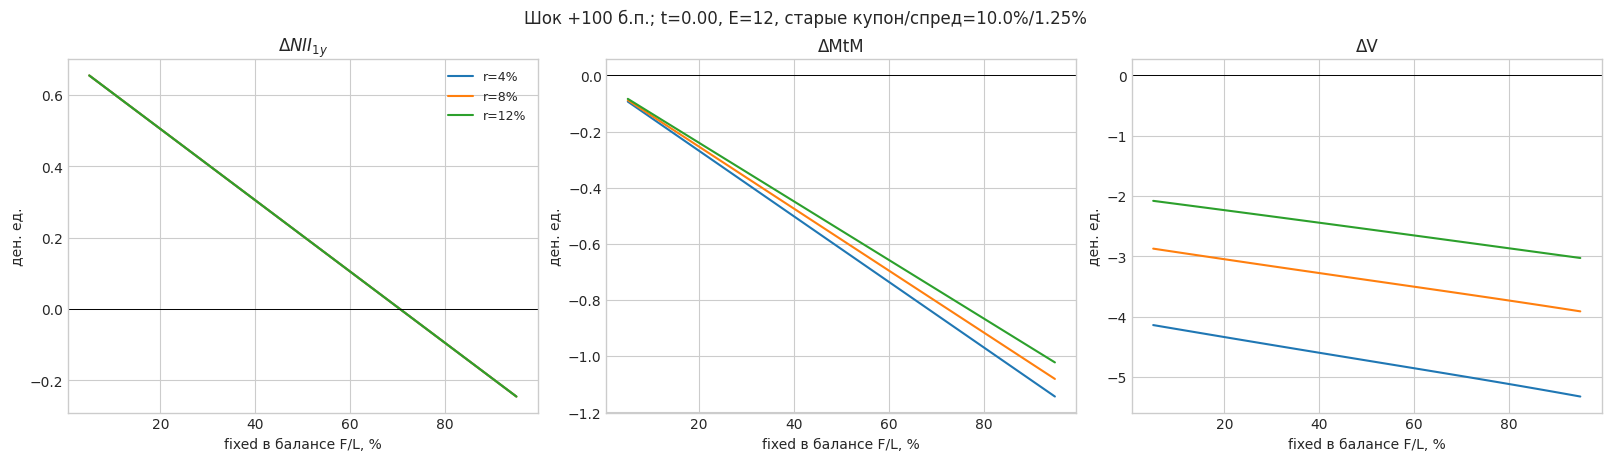

Нулевая ΔNII при F/L=70.5% для выбранного E


In [97]:
RISK_TIME_YEAR = 0.0
RISK_EQUITY = 12.0
OLD_FIXED_COUPON = 0.10
OLD_FLOAT_SPREAD = 0.0125
RISK_LAYER = min(round(RISK_TIME_YEAR / cfg.dt), cfg.steps)
RISK_TIME_YEAR = RISK_LAYER * cfg.dt

def slice_states(rates, fixed_shares):
    loans_now = snapshot_loans(RISK_LAYER)
    f_book = loans_now * fixed_shares
    y_book = OLD_FIXED_COUPON*f_book + OLD_FLOAT_SPREAD*(loans_now-f_book)
    return torch.stack((rates, f_book, y_book,
                        torch.full_like(rates, RISK_EQUITY)), dim=-1)

@torch.no_grad()
def risk_metrics(states_for_slice, layer=RISK_LAYER):
    bump = torch.tensor([shock, 0, 0, 0], device=DEVICE, dtype=dtype)
    output = {'ΔNII_1y': [], 'ΔMtM': [], 'ΔV': []}
    for part in states_for_slice.reshape(-1, 4).split(512):
        loans_now = snapshot_loans(layer)
        deposits_now = snapshot_deposits(loans_now)
        cash = part[:, 3] + deposits_now - loans_now
        output['ΔNII_1y'].append((shock*(loans_now-part[:, 1]+cash-p.deposit_beta*deposits_now)).cpu())
        output['ΔMtM'].append((env.terminal_value(part+bump, loans=batch_loans(part, loans_now))-env.terminal_value(part, loans=batch_loans(part, loans_now))).cpu())
        output['ΔV'].append((solution.value(layer, part+bump, **({"loans": batch_loans(part, loans_now)} if STATIONARY_MODE else {}))-solution.value(layer, part, **({"loans": batch_loans(part, loans_now)} if STATIONARY_MODE else {}))).cpu())
    return {name: torch.cat(parts).reshape(states_for_slice.shape[:-1]).numpy()
            for name, parts in output.items()}

position_grid = torch.linspace(.05, .95, 101, device=DEVICE, dtype=dtype)
rate_levels = (.04, .08, .12)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
for rate, color in zip(rate_levels, plt.get_cmap('tab10').colors[:3]):
    grid_states = slice_states(torch.full_like(position_grid, rate), position_grid)
    result = risk_metrics(grid_states)
    for ax, (name, values) in zip(axes, result.items()):
        ax.plot(100*position_grid.cpu().numpy(), values, label=f'r={rate:.0%}', color=color)
for ax, name in zip(axes, (r'$\Delta NII_{1y}$', 'ΔMtM', 'ΔV')):
    ax.axhline(0, color='black', lw=.7)
    ax.set(xlabel='fixed в балансе F/L, %', ylabel='ден. ед.', title=name)
axes[0].legend(fontsize=9)
fig.suptitle(f'Шок +100 б.п.; t={RISK_TIME_YEAR:.2f}, E={RISK_EQUITY:g}, старые купон/спред={OLD_FIXED_COUPON:.1%}/{OLD_FLOAT_SPREAD:.2%}', fontsize=12)
plt.show()
neutral_fixed_share = (RISK_EQUITY + (1-p.deposit_beta)*snapshot_deposits(snapshot_loans(RISK_LAYER)))/snapshot_loans(RISK_LAYER)
print(f'Нулевая ΔNII при F/L={neutral_fixed_share:.1%} для выбранного E')


### Тепловые карты без повторяющихся поверхностей

Сначала показана одна **базовая поверхность** для трёх метрик при капитале и старых договорах исходной смешанной книги из чекпоинта. Метки 1–5 — точки из сценарной таблицы с теми же капиталом и ставками старых договоров: изменение только $r$ или $F/L$ не создаёт новую поверхность.

Затем показаны **изменения относительно базовой поверхности**. Увеличение купона старых fixed-кредитов меняет $\Delta\mathrm{MtM}$ и $\Delta V$, но оставляет $\Delta NII_{1y}$ неизменной. Уменьшение капитала меняет $\Delta NII_{1y}$ и $\Delta V$, но не $\Delta\mathrm{MtM}$. Поэтому точно повторяющиеся карты не рисуются. Во всех точках $Y=Fk_{F,\mathrm{old}}+(L-F)s_{V,\mathrm{old}}$ пересчитывается при изменении $F/L$; дополнительный шок ставки равен +100 б.п. Карты построены при $t=0$ и размере книги $L_0$; цвета означают денежные единицы.


Контроль дублирования: max |эффект винтажа на ΔNII| = 0; max |эффект капитала на ΔMtM| = 0


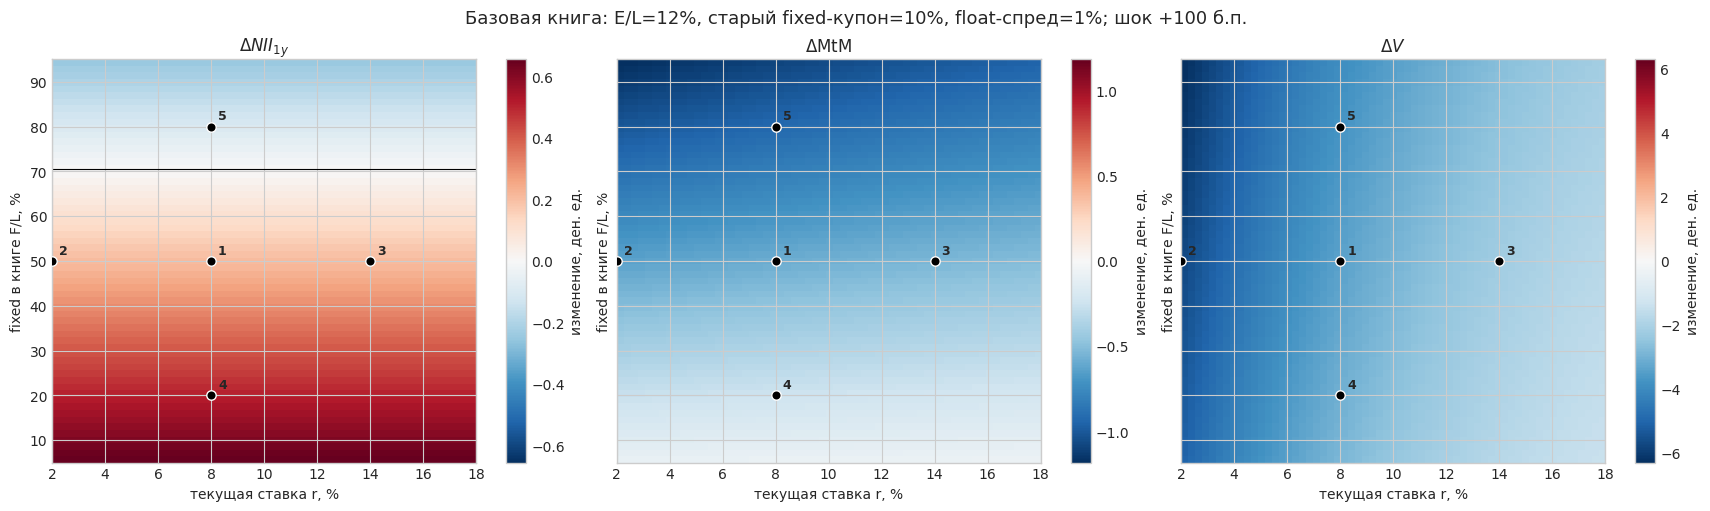

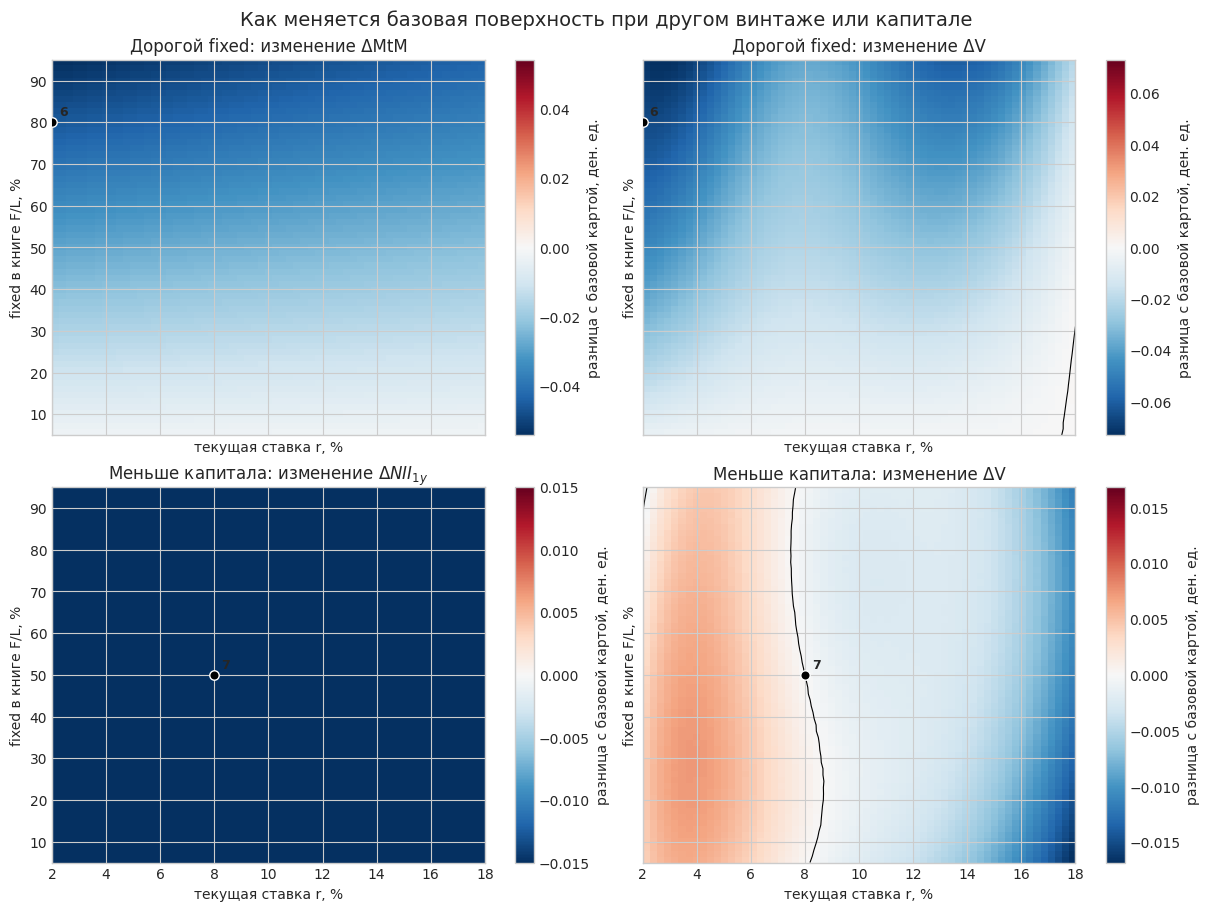

In [98]:
from matplotlib.colors import TwoSlopeNorm
profile_heatmap_n = 17 if os.environ.get('IRRBB_NOTEBOOK_SMOKE') else 61
profile_rates = np.linspace(.02, .18, profile_heatmap_n)
profile_shares = np.linspace(.05, .95, profile_heatmap_n)
profile_rate_mesh, profile_share_mesh = np.meshgrid(profile_rates, profile_shares)
profile_heatmaps = []
profile_specs = [
    ('Опорный винтаж', e_ref, old_fixed_coupon),
    ('Дорогой fixed-винтаж', e_ref, old_fixed_coupon+.02),
    ('Пониженный капитал', max(.105, e_ref-.02), old_fixed_coupon),
]
for _, capital_share, fixed_coupon in profile_specs:
    rate_t = torch.as_tensor(profile_rate_mesh, device=DEVICE, dtype=dtype)
    fixed_t = L_SC*torch.as_tensor(profile_share_mesh, device=DEVICE, dtype=dtype)
    y_t = fixed_t*fixed_coupon + (L_SC-fixed_t)*old_float_spread
    e_t = torch.full_like(rate_t, L_SC*capital_share)
    grid_states = torch.stack((rate_t, fixed_t, y_t, e_t), dim=-1)
    profile_heatmaps.append(scenario_risk_metrics(grid_states))
profile_heatmaps = np.stack(profile_heatmaps)  # профиль, F/L, r, метрика
base_maps = profile_heatmaps[0]
vintage_effect = profile_heatmaps[1] - base_maps
capital_effect = profile_heatmaps[2] - base_maps
print('Контроль дублирования: max |эффект винтажа на ΔNII| = '
      f'{np.max(np.abs(vintage_effect[..., 0])):.3g}; '
      'max |эффект капитала на ΔMtM| = '
      f'{np.max(np.abs(capital_effect[..., 1])):.3g}')

def draw_risk_map(ax, values, title, markers=(), *, difference=False):
    magnitude = max(.01, float(np.abs(values).max()))
    norm = TwoSlopeNorm(vmin=-magnitude, vcenter=0, vmax=magnitude)
    image = ax.imshow(values, origin='lower', aspect='auto', cmap='RdBu_r',
                      extent=[2, 18, 5, 95], norm=norm)
    if values.min() < 0 < values.max():
        ax.contour(profile_rate_mesh*100, profile_share_mesh*100,
                   values, levels=[0], colors='black', linewidths=.8)
    for index in markers:
        _, rate, share, _, _ = scenario_specs[index]
        ax.scatter(100*rate, 100*share, s=46, color='black',
                   edgecolor='white', zorder=3)
        ax.annotate(str(index+1), (100*rate, 100*share),
                    xytext=(5, 5), textcoords='offset points',
                    fontsize=9, weight='bold')
    ax.set(title=title, xlabel='текущая ставка r, %',
           ylabel='fixed в книге F/L, %')
    return image

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True,
                         constrained_layout=True)
for j, ax in enumerate(axes):
    image = draw_risk_map(ax, base_maps[..., j], metric_names[j], range(5))
    fig.colorbar(image, ax=ax, label='изменение, ден. ед.')
fig.suptitle(f'Базовая книга: E/L={e_ref:.0%}, старый fixed-купон={old_fixed_coupon:.0%}, '
             f'float-спред={old_float_spread:.0%}; шок +100 б.п.', fontsize=13)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True,
                         constrained_layout=True)
difference_panels = [
    (axes[0, 0], vintage_effect[..., 1], 'Дорогой fixed: изменение ΔMtM', (5,)),
    (axes[0, 1], vintage_effect[..., 2], 'Дорогой fixed: изменение ΔV', (5,)),
    (axes[1, 0], capital_effect[..., 0], 'Меньше капитала: изменение $\\Delta NII_{1y}$', (6,)),
    (axes[1, 1], capital_effect[..., 2], 'Меньше капитала: изменение ΔV', (6,)),
]
for ax, values, title, markers in difference_panels:
    image = draw_risk_map(ax, values, title, markers, difference=True)
    fig.colorbar(image, ax=ax, label='разница с базовой картой, ден. ед.')
fig.suptitle('Как меняется базовая поверхность при другом винтаже или капитале', fontsize=14)
plt.show()


### Как читать получившиеся карты

Для фиксированного баланса и шока $\delta=0.01$ формула точна:

$$\Delta NII_{1y}=\delta\,[E-F+(1-\beta)D].$$

Поэтому поверхность **не зависит от текущей ставки** $r$, убывает линейно с долей fixed и не зависит от старых купонов $Y$. Нулевая линия проходит при $F/L=[E+(1-\beta)D]/L$; для выбранного капитала её положение печатается выше. Если снизить $E$ на две денежные единицы, вся поверхность сместится ровно на $-0.02$ при шоке +100 б.п.; поэтому разностная карта капитала равномерная.

Для рыночной оценки текущей книги

$$\Delta\mathrm{MtM}=(Y+\mu F)\,[A_Q(r+\delta)-A_Q(r)].$$

Так как $A_Q$ убывает по $r$, метрика здесь отрицательна. При увеличении fixed-книги растёт $Y+\mu F$, поэтому эффект становится сильнее по модулю. При высокой исходной ставке приведённая стоимость оставшихся платежей меньше, и модуль эффекта на этих картах снижается. **Даже при $F=0$ эффект может быть отрицательным**: приведённая стоимость зафиксированных спредов старых float-кредитов тоже зависит от ставки дисконтирования. Изменение капитала не влияет на MtM-дельту, поскольку $E$ вычитается из двух значений MtM. Более высокий купон старых fixed увеличивает её модуль, особенно при большом $F/L$.

На базовой карте $\Delta V$ также отрицательна и по модулю растёт при увеличении fixed-книги. Эта поверхность учитывает **все будущие выплаты и возможность менять новые выдачи**, а не только переоценку текущих договоров. Она более отрицательна при большой fixed-книге и низкой исходной ставке в данном чекпоинте; это наблюдение о калибровке и обученном $V$, а не универсальное свойство IRRBB. Сдвиги капитала и старого купона оцениваются на разностных картах, а подробный срез по $E/L$ приведён ниже. Малые изменения $\Delta V$ нужно сопоставлять с сохранённой невязкой Беллмана и устойчивостью между чекпоинтами.


## Связь ΔMtM и ΔV: форма поверхности и масштаб

Считаем корреляцию по **явно заданной равномерной сетке** $(r,F/L)$ из предыдущего раздела, отдельно для каждого винтажа/уровня капитала. Это описательная характеристика именно выбранного набора состояний, а не оценка с доверительным интервалом для случайной выборки банков. Большая корреляция ожидаема: оба показателя реагируют на ставку и размер старой fixed-книги; при этом связь не обязана быть точной, потому что $\Delta V$ включает будущие потоки, новые выдачи и риск-чувствительный функционал, а $\Delta\mathrm{MtM}$ — переоценку текущих договоров.

Чтобы сравнить **денежные масштабы**, используем $100\Delta M/L_0$ (проценты начальной книги): единицы одинаковы, но горизонт $NII_{1y}$ всё равно составляет один год, а MtM и V капитализируют будущие потоки. Для сравнения только **формы зависимости** ниже также стандартизируем каждую кривую по долям fixed: вычитаем её среднее и делим на стандартное отклонение на выбранном срезе. Такой $z$-показатель не является новой денежной мерой риска.

Опорный винтаж          : Pearson=0.378, Spearman=0.380, R² линейной подгонки=0.143
Дорогой fixed-винтаж    : Pearson=0.388, Spearman=0.389, R² линейной подгонки=0.150
Пониженный капитал      : Pearson=0.379, Spearman=0.381, R² линейной подгонки=0.144
Опорный винтаж: ΔV ≈ -2.328 +1.504·ΔMtM; RMSE остатка=1.070 ден. ед.


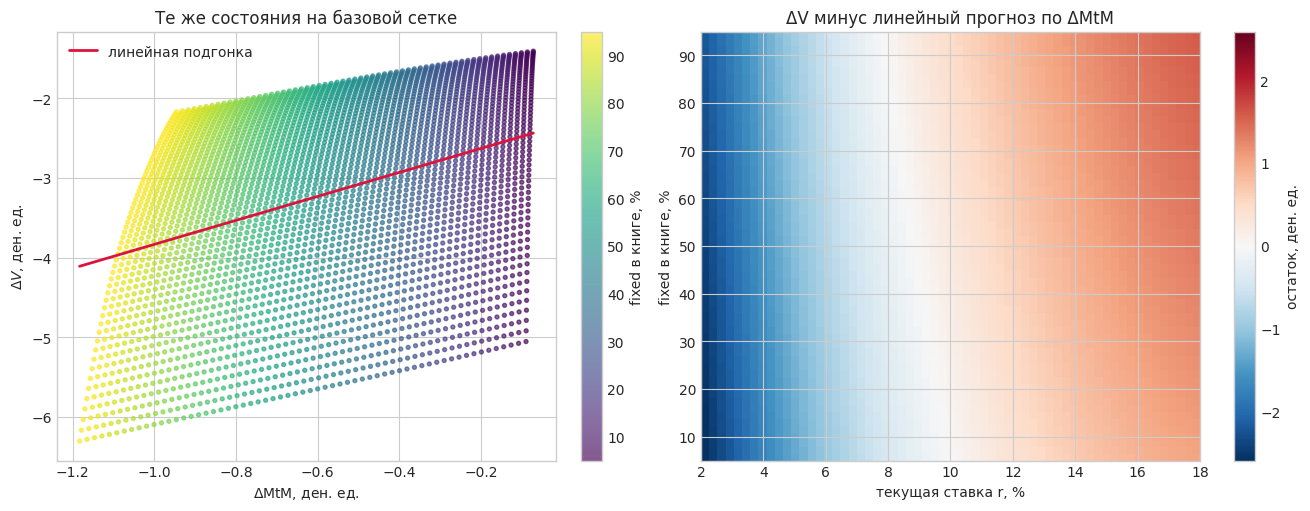

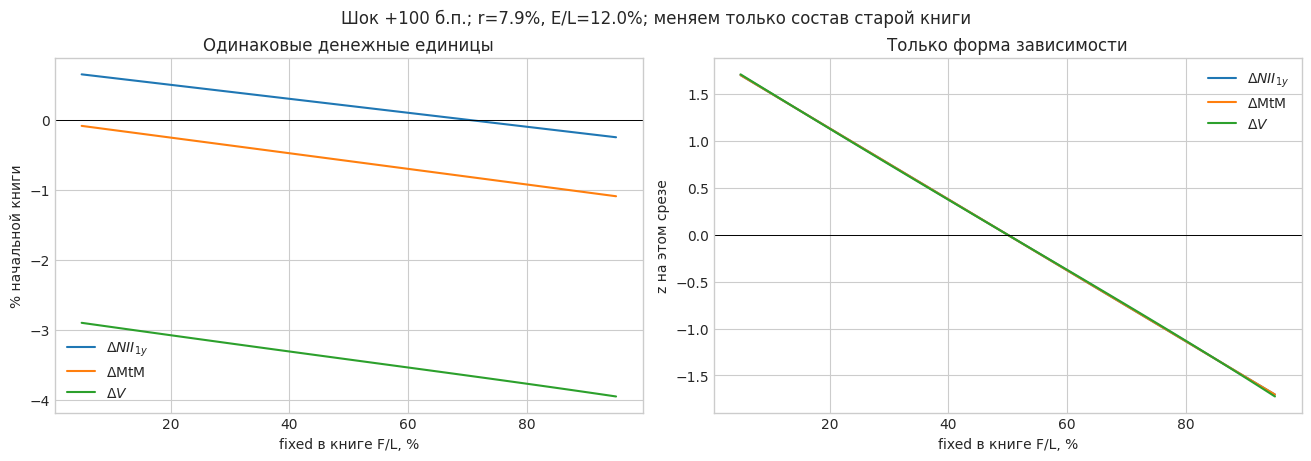

In [99]:
# Одинаковые состояния и веса для каждой пары показателей.
def pearson(a, b):
    return float(np.corrcoef(np.asarray(a).ravel(), np.asarray(b).ravel())[0, 1])

def ranks(a):
    order = np.argsort(np.asarray(a).ravel(), kind='stable')
    rank = np.empty(len(order), dtype=float)
    rank[order] = np.arange(len(order))
    return rank

for profile, maps in zip(profile_specs, profile_heatmaps):
    mtm, value = maps[..., 1], maps[..., 2]
    rho = pearson(mtm, value)
    print(f'{profile[0]:24s}: Pearson={rho:.3f}, Spearman={pearson(ranks(mtm), ranks(value)):.3f}, '
          f'R² линейной подгонки={rho*rho:.3f}')
mtm = base_maps[..., 1].ravel()
value = base_maps[..., 2].ravel()
slope, intercept = np.polyfit(mtm, value, 1)
residual = value - (intercept + slope*mtm)
print(f'Опорный винтаж: ΔV ≈ {intercept:+.3f} {slope:+.3f}·ΔMtM; '
      f'RMSE остатка={np.sqrt(np.mean(residual**2)):.3f} ден. ед.')

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
points = axes[0].scatter(mtm, value, c=profile_share_mesh.ravel()*100,
                         cmap='viridis', s=8, alpha=.65)
line = np.linspace(mtm.min(), mtm.max(), 100)
axes[0].plot(line, intercept+slope*line, color='crimson', lw=2, label='линейная подгонка')
axes[0].set(xlabel=r'$\Delta\mathrm{MtM}$, ден. ед.', ylabel=r'$\Delta V$, ден. ед.',
            title='Те же состояния на базовой сетке')
axes[0].legend()
fig.colorbar(points, ax=axes[0], label='fixed в книге, %')
image = axes[1].imshow(residual.reshape(base_maps.shape[:2]), origin='lower', aspect='auto',
                       cmap='RdBu_r', extent=[2,18,5,95],
                       norm=TwoSlopeNorm(vcenter=0, vmin=-max(.01,np.max(np.abs(residual))),
                                         vmax=max(.01,np.max(np.abs(residual)))))
axes[1].set(xlabel='текущая ставка r, %', ylabel='fixed в книге, %',
            title='ΔV минус линейный прогноз по ΔMtM')
fig.colorbar(image, ax=axes[1], label='остаток, ден. ед.')
plt.show()

rate_index = int(np.argmin(abs(profile_rates-r_ref)))
curves = base_maps[:,rate_index,:]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for j, name in enumerate(metric_names):
    axes[0].plot(profile_shares*100, 100*curves[:,j]/L_SC, label=name)
    standardized = (curves[:,j]-curves[:,j].mean())/curves[:,j].std()
    axes[1].plot(profile_shares*100, standardized, label=name)
axes[0].set(ylabel='% начальной книги', title='Одинаковые денежные единицы')
axes[1].set(ylabel='z на этом срезе', title='Только форма зависимости')
for ax in axes:
    ax.axhline(0, color='black', lw=.7)
    ax.set_xlabel('fixed в книге F/L, %')
    ax.legend()
fig.suptitle(f'Шок +100 б.п.; r={profile_rates[rate_index]:.1%}, '
             f'E/L={e_ref:.1%}; меняем только состав старой книги')
plt.show()

> Ниже сохранён исторический комментарий к прежнему чекпоинту. Для нового запуска выводы следует делать по пересчитанным графикам и числам.

## Что изменилось после уточнения решения?

Для сравнения `stationary_refined2` и `stationary_refined3` держим **одни и те же** $r,F,Y,E$ и экономические параметры. Отчётные `reference_state` у запусков различны, поэтому прежние строки «опорная книга» нельзя сравнивать напрямую. На фиксированном состоянии $\Delta NII_{1y}$ и $\Delta\mathrm{MtM}$ обязаны совпадать между чекпоинтами: они вычисляются по среде, без обученного $V$. Возможны изменения $\Delta V$, выбранного $f$ и одношагового выигрыша от пересмотра действия.

In [100]:
from continuous_time_irrbb.risk_sensitive.stationary_solver import stationary_continuation
COMPARISON_RUNS = ('stationary_refined2', 'stationary_refined3')
comparison_paths = [run_dir.parent / name / 'stationary_solution.pt'
                    for name in COMPARISON_RUNS]
if STATIONARY_MODE and all(path.exists() for path in comparison_paths):
    comparison_solutions = [StationarySolution.load(path, device=DEVICE,
                            dtype=torch.float64) for path in comparison_paths]
    if comparison_solutions[0].environment.p != comparison_solutions[1].environment.p:
        raise ValueError('Сравниваемые запуски имеют разные экономические параметры')
    common_states = torch.tensor([[.08, 50., 5.625, 12.],
                                  [.10, 50., 5.000, 13.]],
                                 device=DEVICE, dtype=torch.float64)
    common_names = ['r=8%, F/L=50%, E/L=12%', 'r=10%, F/L=50%, E/L=13%']
    bump64 = torch.tensor([SCENARIO_SHOCK, 0, 0, 0], device=DEVICE, dtype=torch.float64)
    comparison_results = []
    with torch.no_grad():
        for model in comparison_solutions:
            op = model.operator
            cont = stationary_continuation(model.environment, model.value_net)
            q0 = op.maximize(0, common_states, model.config.dt, cont, action_count=129)
            q1 = op.maximize(0, common_states+bump64, model.config.dt, cont, action_count=129)
            q_locked = op.evaluate(0, common_states+bump64, q0.action,
                                   model.config.dt, cont)
            comparison_results.append(dict(
                delta_v=(model.value(common_states+bump64)-model.value(common_states)).cpu().numpy(),
                f_before=q0.action.cpu().numpy(), f_after=q1.action.cpu().numpy(),
                premium=(q1.value-q_locked).cpu().numpy()))
    print('Одинаковое состояние                  run     ΔV       f до   f после   выигрыш 1 шага')
    for i, label in enumerate(common_names):
        for name, result in zip(COMPARISON_RUNS, comparison_results):
            print(f'{label:38s} {name[-1]}   {result["delta_v"][i]:+8.5f}  '
                  f'{result["f_before"][i]:.3f}   {result["f_after"][i]:.3f}   '
                  f'{result["premium"][i]:.6f}')
    print('Изменение ΔV между запусками в тех же состояниях:',
          np.round(comparison_results[1]['delta_v']-comparison_results[0]['delta_v'], 6))
else:
    print('Сравнение пропущено: требуются оба стационарных чекпоинта в runs/.')

Одинаковое состояние                  run     ΔV       f до   f после   выигрыш 1 шага
r=8%, F/L=50%, E/L=12%                 2   -1.81840  0.469   0.438   0.000167
r=8%, F/L=50%, E/L=12%                 3   -1.91126  0.406   0.383   0.000143
r=10%, F/L=50%, E/L=13%                2   -1.71941  0.422   0.391   0.000190
r=10%, F/L=50%, E/L=13%                3   -1.81076  0.359   0.336   0.000156
Изменение ΔV между запусками в тех же состояниях: [-0.092865 -0.09135 ]


## Сценарии с разным капиталом $E/L$

Фиксируем ставку, старую книгу $(F,Y)$, объём кредитов и депозитов; меняем только $E$. Тогда cash равен $C=E+D-L$, то есть здесь больший капитал означает больший денежный буфер. $E/L$ — **модельное приближение CAR**, без весов риска. При +100 б.п. $\Delta NII_{1y}=\delta[E-F+(1-\beta)D]$ растёт ровно на $\delta\,\Delta E$. $\Delta\mathrm{MtM}$ **точно не зависит** от $E$ при фиксированных $(r,F,Y)$. Зависимость $\Delta V$ определяется экономикой будущих выплат, финансирования и риск-чувствительным управлением; в этой калибровке она может оказаться очень слабой.

Фиксированы r=8.0%, F/L=50.0%, Y=5.625; шок +1%; C/L=E/L-10.0%
E/L     C/L      ΔNII_1y       ΔMtM          ΔV
12.0%    2.0%     +0.20500    -0.58440    -3.39009
14.0%    4.0%     +0.22500    -0.58440    -3.38620
16.0%    6.0%     +0.24500    -0.58440    -3.37733
20.0%   10.0%     +0.28500    -0.58440    -3.34250
ΔV(20% CAR) − ΔV(12% CAR) = +0.047592


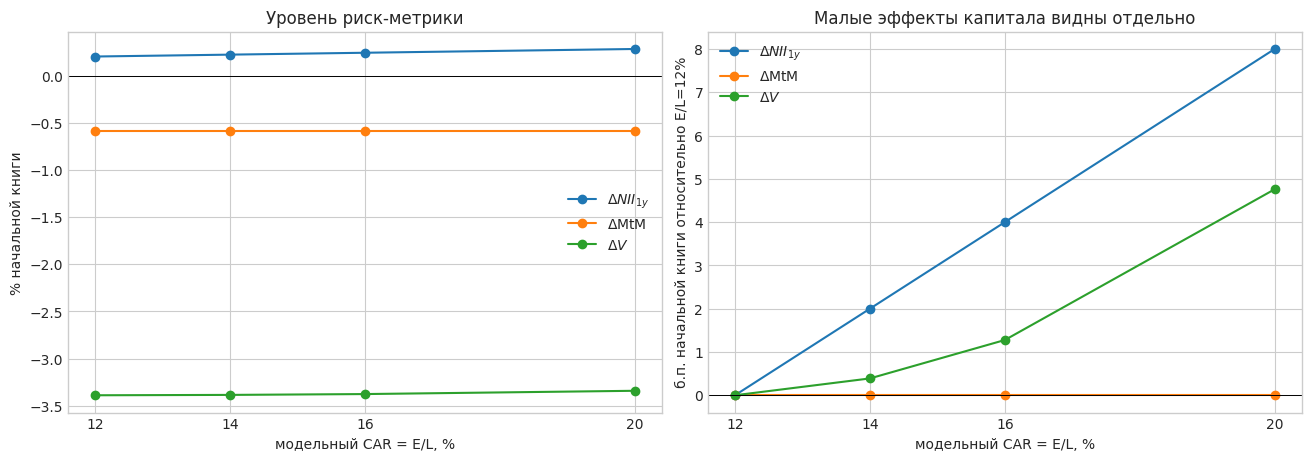

In [101]:
CAR_LEVELS = np.array([.12, .14, .16, .20])
car_states = torch.tensor([[r_ref, F_ref, Y_ref, L_SC*car]
                           for car in CAR_LEVELS], device=DEVICE, dtype=dtype)
car_deltas = scenario_risk_metrics(car_states)
print(f'Фиксированы r={r_ref:.1%}, F/L={F_ref/L_SC:.1%}, Y={Y_ref:.3f}; '
      f'шок +{SCENARIO_SHOCK:.0%}; C/L=E/L{D_SC/L_SC-1:+.1%}')
print('E/L     C/L      ΔNII_1y       ΔMtM          ΔV')
for car, row in zip(CAR_LEVELS, car_deltas):
    print(f'{car:5.1%}  {car+D_SC/L_SC-1:6.1%}   {row[0]:+10.5f}  '
          f'{row[1]:+10.5f}  {row[2]:+10.5f}')
print('ΔV(20% CAR) − ΔV(12% CAR) =', f'{car_deltas[-1,2]-car_deltas[0,2]:+.6f}')
fig, axes = plt.subplots(1,2,figsize=(13,4.5),constrained_layout=True)
for j, name in enumerate(metric_names):
    axes[0].plot(CAR_LEVELS*100, 100*car_deltas[:,j]/L_SC,
                 marker='o', label=name)
    axes[1].plot(CAR_LEVELS*100, 10000*(car_deltas[:,j]-car_deltas[0,j])/L_SC,
                 marker='o', label=name)
axes[0].set(ylabel='% начальной книги',title='Уровень риск-метрики')
axes[1].set(ylabel='б.п. начальной книги относительно E/L=12%',
            title='Малые эффекты капитала видны отдельно')
for ax in axes:
    ax.set_xlabel('модельный CAR = E/L, %')
    ax.set_xticks(CAR_LEVELS*100)
    ax.axhline(0, color='black', lw=.7)
    ax.legend()
plt.show()

> Ниже сохранён исторический комментарий к прежнему чекпоинту. Для нового запуска выводы следует делать по пересчитанным графикам и числам.

На уровне формул изменение капитала с 12% до 20% книги повышает $\Delta NII_{1y}$ на $0.08$ денежной единицы и оставляет $\Delta\mathrm{MtM}$ прежней. Небольшое изменение $\Delta V$ на графике — **результат приближённого решения**, а не доказанный структурный эффект: сравните его с невязкой Беллмана и поведением обоих чекпоинтов в предыдущем разделе. Для настоящего регуляторного CAR понадобились бы риск-взвешенные активы и отдельные правила капитала.

## Что даёт пересмотр управления после шока?

Нельзя считать $\Delta V-\Delta\mathrm{MtM}$ «выгодой от управления»: величины оценивают разные потоки и используют разные правила дисконтирования. Для **контролируемого сравнения при одном и том же функционале** ниже вычисляем одношаговый оператор Беллмана $Q(x,f)$. В исходном состоянии выбираем $f_0=\arg\max_f Q(x,f)$. В шокированном состоянии сравниваем $\max_f Q(x^+,f)$ с $Q(x^+,f_0)$. Разность неотрицательна и показывает цену возможности **немедленно изменить следующую выдачу**. В обоих вариантах после одного шага стоит одно и то же приближение $V$ и разрешено дальнейшее оптимальное управление. Поэтому это **не** оценка полного эффекта заморозки политики на всём горизонте, тем более не разность с run-off MtM.

Для диагностики перечитываем тот же чекпоинт в `float64`, чтобы маленькая разность двух близких значений $Q$ не терялась при округлении. Это повышает точность вычисления, но не устраняет ошибку обучения $V$.

Сценарий                              f до   f после    ΔQ адапт.   ΔQ старое f  выигрыш 1 шага
Исходная книга: 50% fixed             0.055    0.047      -3.3924      -3.3925      0.000023
Низкая ставка, те же договоры         0.203    0.172      -5.7094      -5.7097      0.000336
Высокая ставка, те же договоры        0.008    0.000      -2.2237      -2.2237      0.000002
20% fixed в книге                     0.125    0.109      -3.0448      -3.0449      0.000045
80% fixed в книге                     0.008    0.000      -3.7391      -3.7391      0.000041
Низкая ставка + дорогой fixed         0.180    0.148      -6.1980      -6.1984      0.000352
Пониженный капитал                    0.055    0.047      -3.3922      -3.3923      0.000023
Вся книга — float (0% fixed)          0.195    0.180      -2.8104      -2.8105      0.000060
Вся книга — fixed (100% fixed)        0.000    0.000      -3.9773      -3.9773      0.000000
Последняя сохранённая Bellman RMSE: 0.00643276609480381


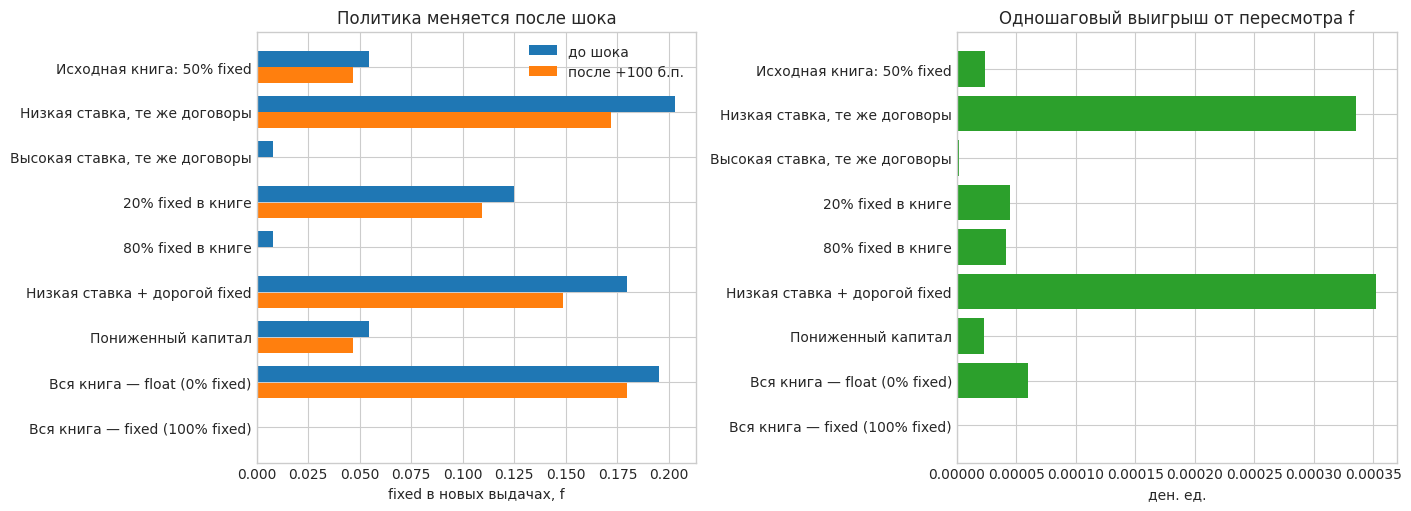

In [102]:
from continuous_time_irrbb.risk_sensitive.stationary_solver import stationary_continuation
if STATIONARY_MODE:
    diagnostic = StationarySolution.load(run_dir / 'stationary_solution.pt',
                                         device=DEVICE, dtype=torch.float64)
    continuation = stationary_continuation(diagnostic.environment, diagnostic.value_net)
else:
    diagnostic = FittedSolution.load(run_dir / 'solution.pt',
                                     device=DEVICE, dtype=torch.float64)
    continuation = lambda time, x: diagnostic.value(1, x)
operator = diagnostic.operator
x0 = scenario_states.to(dtype=torch.float64)
x1 = x0 + torch.tensor([SCENARIO_SHOCK,0,0,0], device=DEVICE, dtype=torch.float64)
ACTION_DIAGNOSTIC_GRID = 129
with torch.no_grad():
    baseline_q = operator.maximize(0, x0, cfg.dt, continuation,
                                   action_count=ACTION_DIAGNOSTIC_GRID)
    shocked_q = operator.maximize(0, x1, cfg.dt, continuation,
                                  action_count=ACTION_DIAGNOSTIC_GRID)
    locked_q = operator.evaluate(0, x1, baseline_q.action, cfg.dt, continuation)
    premium = (shocked_q.value - locked_q).cpu().numpy()
    before = baseline_q.action.cpu().numpy()
    after = shocked_q.action.cpu().numpy()
    delta_q = (shocked_q.value-baseline_q.value).cpu().numpy()
    locked_delta_q = (locked_q-baseline_q.value).cpu().numpy()
assert np.all(premium >= -1e-9)
print('Сценарий                              f до   f после    ΔQ адапт.   ΔQ старое f  выигрыш 1 шага')
for spec, f0, f1, dv_a, dv_l, gain in zip(scenario_specs, before, after,
                                          delta_q, locked_delta_q, premium):
    print(f'{spec[0]:36s} {f0:6.3f}  {f1:7.3f}    {dv_a:+9.4f}    {dv_l:+9.4f}      {gain:.6f}')
print('Последняя сохранённая Bellman RMSE:',
      (report.get('diagnostics') or [{}])[-1].get('bellman_rmse', 'нет данных'))

fig, axes = plt.subplots(1,2,figsize=(14,5),constrained_layout=True)
y = np.arange(len(scenario_specs))
labels = [s[0] for s in scenario_specs]
axes[0].barh(y-.18,before,height=.34,label='до шока')
axes[0].barh(y+.18,after,height=.34,label='после +100 б.п.')
axes[0].set(xlabel='fixed в новых выдачах, f', title='Политика меняется после шока')
axes[0].set_yticks(y,labels)
axes[0].invert_yaxis()
axes[0].legend()
axes[1].barh(y, premium, color='tab:green')
axes[1].set(xlabel='ден. ед.', title='Одношаговый выигрыш от пересмотра f')
axes[1].set_yticks(y,labels)
axes[1].invert_yaxis()
plt.show()

> Ниже сохранён исторический комментарий к прежнему чекпоинту. Для нового запуска выводы следует делать по пересчитанным графикам и числам.

**Интерпретация.** При текущем чекпоинте после шока $f$ меняется, но одношаговый выигрыш от этого обычно порядка $10^{-4}$ денежных единиц, тогда как сама $\Delta V$ порядка единицы. Он существенно меньше сохранённой невязки Беллмана. Поэтому эти расчёты **не подтверждают**, что возможность изменить следующую выдачу заметно снижает IRRBB-чувствительность в данной калибровке. Сильная корреляция с $\Delta\mathrm{MtM}$ совместима с тем, что риск старой книги доминирует над эффектом немедленной корректировки новых выдач. Полное сравнение двух политик на бесконечном горизонте приведено ниже.
При гладком внутреннем максимуме эта малость имеет математическое объяснение. Если $f^*(x)$ оптимально до шока и $Q_{ff}<0$, то сдвиг $f^*$ при малом $\delta$ имеет порядок $O(\delta)$, а выигрыш от замены старого действия новым — порядок $O(\delta^2)$, поскольку $Q_f(x,f^*(x))=0$. Первая производная оптимизированного $V$ по ставке по теореме об огибающей **не содержит отдельного первого порядка от изменения $f^*$**. Это верно локально при внутреннем гладком оптимуме; на границе действия или при негладком переключении вывод может измениться. Поэтому заметное изменение самого $f$ ещё не означает заметного снижения $|\Delta V|$ при шоке +100 б.п.


### Полный горизонт: адаптивная политика и постоянная доля новых выдач

Сравниваем **один и тот же** рекурсивный риск-чувствительный функционал. В первом варианте в каждом будущем состоянии применяется выученная обратная связь $\pi(x)$. Во втором доля fixed **в каждой новой выдаче** навсегда равна $f_0=\pi(x_0)$, выбранной до шока. В обоих случаях старая книга амортизируется, новая книга растёт, ставка случайна, а прибыль и дивиденды пересчитываются на всём горизонте. Это сравнение не тождественно run-off $\Delta\mathrm{MtM}$.

Пусть $J^\pi$ и $J^{f_0}$ — значения этих двух политик, каждое удовлетворяет своему уравнению Беллмана с тем же оператором денежных потоков. Полная премия адаптации $A(x)=J^\pi(x)-J^{f_0}(x)$. Тогда **точное тождество** для вклада управления в чувствительность имеет вид
$$\Delta J^\pi-\Delta J^{f_0}=A(x^+)-A(x).$$
Оно включает **все** будущие решения и вызванные ими изменения потоков. Здесь $x^+$ отличается от $x$ только повышением текущей ставки на 100 б.п. Сами $J$ ниже рассчитаны приближённой итерацией Беллмана; точность тождества не делает их численные оценки точными.

Для сопоставимости мы заново оценили обе фиксированные стратегии на одинаковом наборе состояний, дважды с разными случайными сетками. Исходное приближение оптимального $V$ не подставляется напрямую: его систематическая ошибка уровня способна создать ложную «премию». Показанные отчёты относятся к `stationary_refined3`; для другого чекпоинта запустите скрипты `evaluate_frozen_policy.py` и `evaluate_feedback_policy.py` заново.


In [103]:
from pathlib import Path
import json

# Новые запуски evaluate_feedback_policy.py сохраняют report.json в feedback_eval/.
# Компактные seed_*.json от прежних расчётов читаем, только если новых отчётов нет.
full_eval_reports = []
if STATIONARY_MODE:
    fresh_paths = sorted(run_dir.glob('feedback_eval*/report.json'))
    if fresh_paths:
        report_paths = fresh_paths
    else:
        report_paths = sorted((run_dir / 'full_horizon_evaluation').glob('seed_*.json'))
    for path in report_paths:
        report = json.loads(path.read_text(encoding='utf-8'))
        if Path(report['source_checkpoint']).parent.name != run_dir.name:
            print(f'Пропущен отчёт другого чекпоинта: {path}')
            continue
        report['seed'] = int(report.get('seed', report.get('config', {}).get('seed', 0)))
        full_eval_reports.append(report)
    if report_paths:
        print('Прочитаны отчёты:', ', '.join(str(path) for path in report_paths))
if not full_eval_reports:
    print('Для текущего чекпоинта нет полной переоценки политик. Запустите оба скрипта оценки.')
else:
    print('seed    f0      ΔJ feedback    ΔJ fixed    A(base)    A(shock)    ΔA')
    for q in full_eval_reports:
        print(f"{q['seed']:4d}  {q['frozen_fixed_share']:.4f}   "
              f"{q['feedback_delta_v']:+.6f}     {q['frozen_delta_v']:+.6f}   "
              f"{q['premium_base']:+.6f}  {q['premium_shock']:+.6f}  "
              f"{q['change_in_adaptation_premium']:+.6f}")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
    for q in full_eval_reports:
        axes[0].plot([0, 1], [q['premium_base'], q['premium_shock']], marker='o',
                     label=f"seed {q['seed']}")
        axes[1].scatter(q['seed'], q['change_in_adaptation_premium'], s=65)
    axes[0].axhline(0, color='black', linewidth=.7)
    axes[1].axhline(0, color='black', linewidth=.7)
    axes[0].set(xticks=[0,1], xticklabels=['до шока', 'после шока'],
                ylabel='A(x) = J feedback − J fixed',
                title='Полная премия управления')
    axes[1].set(xticks=[q['seed'] for q in full_eval_reports],
                xlabel='случайная сетка оценки', ylabel='A(x⁺) − A(x)',
                title='Вклад управления в ΔV')
    axes[0].legend()
    plt.show()
    if any(not q['converged_on_validation_cloud'] for q in full_eval_reports):
        print('Внимание: оценка политик не сошлась по контрольной невязке; '
              'полученная разность не является точной оценкой эффекта.')
    if any(q['premium_base'] < 0 or q['premium_shock'] < 0 for q in full_eval_reports):
        print('В одном прогоне нарушено ожидаемое неравенство J feedback ≥ J fixed; '
              'точная величина премии и её изменение здесь не установлены.')


Для текущего чекпоинта нет полной переоценки политик. Запустите оба скрипта оценки.


> Ниже сохранён исторический комментарий к прежнему чекпоинту. Для нового запуска выводы следует делать по пересчитанным графикам и числам.

**Интерпретация полного горизонта.** В показанном сохранённом запуске премия адаптивной политики относительно неизменной доли новых fixed-выдач составляет примерно $A(x)=+0.0410$ до шока и $A(x^+)=+0.0399$ после шока. Следовательно, её вклад именно в чувствительность равен $\Delta A\approx-0.00114$, тогда как обе полные чувствительности $\Delta J^\pi$ и $\Delta J^{f_0}$ близки к $-1.815$. Это различие между **ценностью возможности реагировать на будущие состояния** и **изменением этой ценности при данном шоке**. Обе стратегии наследуют одну и ту же старую книгу; $f_0=\pi(x)$, поэтому сначала они почти совпадают. После шока действие меняется умеренно, а большая часть ставки возвращается к среднему под $P$. Поэтому обе стратегии могут терять почти одинаковую стоимость, даже если управление полезно на всём горизонте. Отрицательное $\Delta A$ в этом запуске означало бы, что адаптация слегка усиливает потерю от шока, а не хеджирует её. Однако ни величину, ни знак пока нельзя считать установленными: оценка политик не сошлась по контрольной невязке, а последняя невязка исходного чекпоинта около $0.005$ превышает исследуемый эффект $0.00114$. Нужна проверка на независимых сетках и при более точной оценке обеих стратегий.


### Почему $|\Delta V|$ может превышать $|\Delta\mathrm{MtM}|$

$\Delta\mathrm{MtM}$ переоценивает **существующие договоры**. $\Delta V$ меняет оценку потока владельцу на всём будущем горизонте, включая будущие выдачи, финансирование, дивиденды и риск-чувствительное продолжение задачи. Возможность адаптировать управление повышает стоимость *относительно того же функционала с принудительно сохранённым действием*, но не обязывает $|\Delta V|$ быть меньше $|\Delta\mathrm{MtM}|$: сравниваются разные объекты.

Следующий рисунок раскладывает **один шаг** оператора Беллмана в опорном состоянии. Для старого действия $f_0$ и $Q(x,f)=d(x,f)+D(x)\,CE_\gamma[V(X')]$ имеем
$$\Delta Q_{\rm old\ f}=\Delta d+(D_+-D_0)CE_0+D_+(CE_+-CE_0).$$
Добавив $\max_fQ(x^+,f)-Q(x^+,f_0)$, получим изменение оптимизированного $Q$. Третье слагаемое включает **всю будущую задачу**, а не только будущие новые кредиты. Разложение зависит от длины шага и способа группировки; это вычислительная диагностика, не уникальная экономическая атрибуция.

Исходная смешанная книга; вклад в изменение Q, ден. ед.:
  Ближайший поток владельцу              +0.046887
  Дисконтирование продолжения            -0.220919
  Изменение стоимости продолжения        -3.218431
  Пересмотр следующего f                 +0.000023
Сумма ΔQ=-3.392440; ΔV сети=-3.390091; ΔMtM=-0.584404; ΔV−ΔMtM=-2.805686


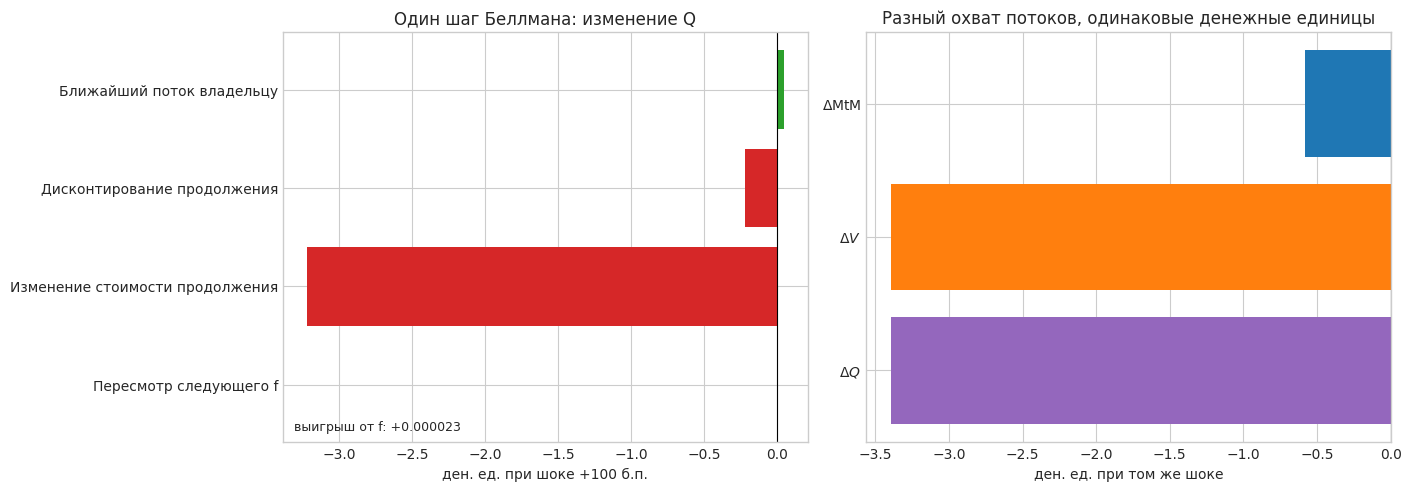

In [104]:
@torch.no_grad()
def bellman_pieces(state, action):
    n = operator.normal_nodes.numel()
    expanded_state = state.unsqueeze(-2).expand(1, n, 4)
    expanded_action = action.unsqueeze(-1).expand(1, n)
    nodes = operator.normal_nodes.to(state).expand(1, n)
    transition = diagnostic.environment.step(expanded_state, expanded_action,
                                              nodes, cfg.dt, time=0, validate=False)
    future = continuation(cfg.dt, transition.state, **({"book_growth": transition.book_growth} if STATIONARY_MODE and p.growth_rate_sensitivity else {}))
    weights = operator.normal_weights.to(state)
    if operator.risk_aversion == 0:
        ce = (weights*future).sum(-1)
    else:
        ce = -torch.logsumexp(weights.log()-operator.risk_aversion*future,
                              dim=-1)/operator.risk_aversion
    return (transition.dividend_pv[...,0].item(),
            transition.discount[...,0].item(), ce.item())

ref_action = baseline_q.action[:1]
d0, discount0, ce0 = bellman_pieces(x0[:1], ref_action)
d1, discount1, ce1 = bellman_pieces(x1[:1], ref_action)
contributions = np.array([d1-d0,
                          (discount1-discount0)*ce0,
                          discount1*(ce1-ce0),
                          premium[0]])
q_change = (shocked_q.value[0]-baseline_q.value[0]).item()
assert abs(contributions.sum()-q_change) < 1e-7
mtm_change, v_change = scenario_deltas[0,1], scenario_deltas[0,2]
labels = ['Ближайший поток владельцу', 'Дисконтирование продолжения',
          'Изменение стоимости продолжения', 'Пересмотр следующего f']
print('Исходная смешанная книга; вклад в изменение Q, ден. ед.:')
for label, value in zip(labels, contributions):
    print(f'  {label:38s} {value:+.6f}')
print(f'Сумма ΔQ={q_change:+.6f}; ΔV сети={v_change:+.6f}; '
      f'ΔMtM={mtm_change:+.6f}; ΔV−ΔMtM={v_change-mtm_change:+.6f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True)
y = np.arange(len(labels))
axes[0].barh(y, contributions,
             color=np.where(contributions >= 0, 'tab:green', 'tab:red'))
axes[0].set_yticks(y, labels)
axes[0].invert_yaxis()
axes[0].axvline(0,color='black',lw=.8)
axes[0].set(xlabel='ден. ед. при шоке +100 б.п.',
            title='Один шаг Беллмана: изменение Q')
axes[0].annotate(f'выигрыш от f: {contributions[-1]:+.6f}',
                 xy=(.02,.03),xycoords='axes fraction',fontsize=9)
compare = np.array([mtm_change, v_change, q_change])
axes[1].barh(np.arange(3), compare, color=['tab:blue','tab:orange','tab:purple'])
axes[1].set_yticks(np.arange(3), [r'$\Delta\mathrm{MtM}$',r'$\Delta V$',r'$\Delta Q$'])
axes[1].invert_yaxis()
axes[1].axvline(0,color='black',lw=.8)
axes[1].set(xlabel='ден. ед. при том же шоке',
            title='Разный охват потоков, одинаковые денежные единицы')
plt.show()

> Ниже сохранён исторический комментарий к прежнему чекпоинту. Для нового запуска выводы следует делать по пересчитанным графикам и числам.

В данном чекпоинте выигрыш от немедленной смены $f$ на несколько порядков меньше изменения продолжения. Это подтверждает, что **сравнивать $\Delta V$ с $\Delta\mathrm{MtM}$ как «до и после управления» неверно**. Даже большой отрицательный вклад продолжения нельзя целиком назвать потерей будущих выдач: в нём присутствуют старая книга, будущие ставки, фондирование, дисконтирование и все более поздние решения. Для отдельной оценки стоимости будущего бизнеса нужна контрфактическая модель, которая отключает новые выдачи или оценивает две политики при одном и том же функционале.

## Срез обратной связи в одинаковых состояниях

Последний рисунок меняет ставку и **существующую** долю fixed, удерживая $E=12$ и старую книгу $Y=0.10F+0.0125(L-F)$ одинаково определённой для всех точек. Цвет — новая доля fixed, которую выбирает чекпоинт. Это срез сети, а не доказанная карта оптимума. При сравнении разных запусков учитывайте `quality_flags` в отчётах.

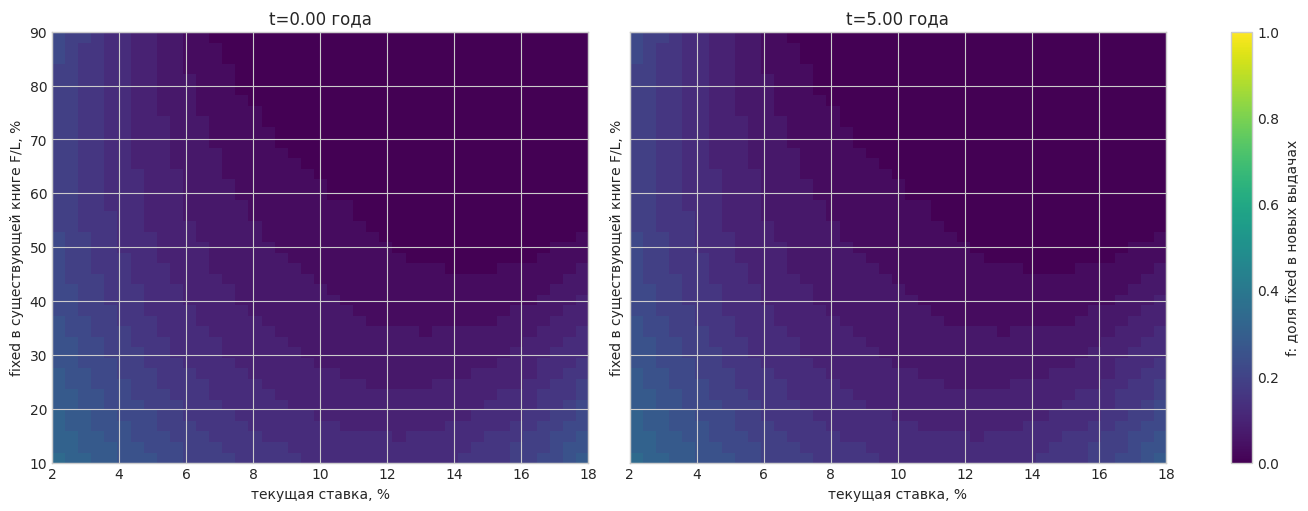

In [105]:
grid_n = 13 if os.environ.get("IRRBB_NOTEBOOK_SMOKE") else 41
r_grid = torch.linspace(.02, .18, grid_n, device=DEVICE, dtype=dtype)
book_grid = torch.linspace(.1, .9, grid_n, device=DEVICE, dtype=dtype)
rr, bb = torch.meshgrid(r_grid, book_grid, indexing="ij")
fig, ax = plt.subplots(1, 2, figsize=(13, 5), sharey=True, constrained_layout=True)
for a, layer in zip(ax, (0, cfg.steps//2)):
    loans_now = snapshot_loans(layer)
    ff = bb * loans_now
    yy = .10*ff + .0125*(loans_now-ff)
    xx = torch.stack((rr, ff, yy, torch.full_like(rr, .12*loans_now)), -1).reshape(-1, 4)
    with torch.no_grad():
        policy = torch.cat([solution.action(layer, part, action_count=POLICY_GRID, **({"loans": batch_loans(part, loans_now)} if STATIONARY_MODE else {}))
                            for part in xx.split(128)]).reshape(grid_n, grid_n).cpu().numpy()
    im = a.imshow(policy.T, origin="lower", extent=[2,18,10,90], vmin=0, vmax=1,
                  aspect="auto", cmap="viridis")
    a.set_title(f"t={layer*cfg.dt:.2f} года")
    a.set_xlabel("текущая ставка, %")
    a.set_ylabel("fixed в существующей книге F/L, %")
fig.colorbar(im, ax=ax, label="f: доля fixed в новых выдачах")
plt.show()
